<a href="https://colab.research.google.com/github/benh7-max/ast457_2026_Fall/blob/main/Copy_of_HarmonicOscillatorFA26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Harmonic Oscillator

* **Author: Ben Hall-Skank**

* **Date: 10/18/26**

* **Time spent on this assignment: 6hrs**

In this assignment you will explore uncertainty, energy eigenstates, time evolution, and raising and lowering operators for a quantum harmonic oscillator. You will compare quantum predictions with classical motion and investigate how numerical approximations can produce misleading results.

**Code in this notebook.** No prior coding experience is needed, but you will *read* and *change* code. The key formulas from lecture (expectation values and uncertainties, the Hamiltonian, the Hermite-function eigenstates, time evolution, and the ladder operators) are written out in the exercise cells. The comment next to each line says which formula it implements. Supporting machinery (grids, Fourier transforms, error checks, plotting) lives in the three setup cells. You are welcome to read it, but you do not need to.

**Playground.** Lines marked `# >>> TRY CHANGING` are knobs you can turn. Question parts labelled **(Playground)** require you to change a value or add a case and report what you observed; everywhere else, experimenting is encouraged but optional. Many playground cells take a *list* of values: **add** your values to the list rather than replacing the defaults, so that every case appears in the same run and survives **Restart and Run All**. The original values are noted in the comments, so you can always change things back. If a cell gives an error you do not understand, read the message (most errors explain what to change) and then ask a TA.

**Units.** We use the oscillator length $\ell=\sqrt{\hbar/(m\omega)}$ for position, $\hbar/\ell$ for momentum, $\hbar\omega$ for energy, and $1/\omega$ for time. In these dimensionless variables $\hbar=m=\omega=1$, so $V(x)=x^2/2$ and one classical period is $2\pi$. Comparisons of numerical position and momentum widths below refer to these respective oscillator units.

**State labels.** Oscillator states are labelled $n=0,1,2,\ldots$, starting with the ground state $n=0$. The wells assignment used labels starting at 1. In this notebook, both the physical oscillator label and the Python column index start at 0.

### How to answer and what to submit

Your answers are read by a person. Write in complete sentences, explain the physical reason behind your claims, and identify the plot features or numerical results that support them. A number alone is not an explanation. Where a prediction is requested, think about it before revealing the supplied output; an observation that differs from your prediction is a useful starting point for an explanation.

Keep the figures and numerical results you refer to in your submission. The default comparisons run automatically. For **(Playground)** parts, leave the values you tried in the code (added to the lists), so that your figures are regenerated whenever the notebook is rerun. Label any additional evidence.

**What to hand in:** your executed `.ipynb` file and a PDF of your answers. The PDF may include the supporting output, or it may refer to clearly identified figures and results in your executed notebook (for example, “Question 8, relative-phase comparison”). In either format, include your parameter choices and explanations. Instructions are at the end.

### Running the notebook

In Google Colab, upload the notebook and use **File > Save a copy in Drive** before working. In Jupyter or JupyterLab, open the file and save your own copy. Run the three supplied setup cells below in order. They import NumPy, SciPy, Matplotlib, and IPython, then define the physics functions separately from the plotting functions. A local installation also needs Jupyter; Colab provides these packages.

You do not need to edit the helper functions. Their documentation explains the physics and numerical conventions if you want to inspect them. If a name is undefined, restart the kernel/session and run the cells in order.

`SHOW_ANIMATIONS = False` keeps the notebook ready for printing. Set it to `True` to display the supplied animations as well. **Every question can be answered using the static figures and printed results.** Turning animations off does not remove any calculation or question.

The area under a probability-density curve is one. The height of the curve describes how likely measurements are to fall near a particular position or momentum.

In [1]:
import sys
import numpy as np                                   # arrays and linear algebra
import scipy                                         # scientific computing library
import matplotlib.pyplot as plt                      # plotting
from scipy.linalg import eigh_tridiagonal, eig_banded  # eigenvalue solvers for banded matrices
from scipy.optimize import minimize                  # numerical minimization (Exercise 1c)
from scipy.sparse import diags, eye                  # sparse matrices: store only the nonzero diagonals
from scipy.special import eval_hermite, factorial    # Hermite polynomials H_n(x) and n!
from matplotlib.animation import FuncAnimation       # animation
from IPython.display import HTML, display            # show animations in the notebook

plt.rcParams.update({'font.size': 11, 'figure.dpi': 100,
                     'animation.embed_limit': 30})

# Set this to True to add animations. They are not needed for any question, and they
# do not print, so set it back to False before making your PDF.
SHOW_ANIMATIONS = True

print(f'Python {sys.version.split()[0]} | NumPy {np.__version__} | SciPy {scipy.__version__}')

Python 3.13.18 | NumPy 2.1.3 | SciPy 1.16.3


In [2]:
# =============================================================================
# PHYSICS HELPER FUNCTIONS
# -----------------------------------------------------------------------------
# You do not need to edit this cell, but you are encouraged to read it. The
# central formulas of the course are written out AGAIN, line by line, in the
# exercise cells where they are used; this cell holds the supporting machinery
# (grids, Fourier transforms, statistics, and checks that catch common
# numerical problems) and versions of the same steps that later cells reuse.
#
# Units: hbar = m = omega = 1, so
#     H = p^2/2 + x^2/2,     E_n = n + 1/2,     one classical period = 2*pi.
#
# The same quantum state appears in two normalizations (as in the wells notebook):
#   psi -- "grid-normalized" vector with sum_j |psi_j|^2 = 1. This is what a
#          matrix eigenvalue solver returns. |psi_j|^2 is the PROBABILITY of
#          finding the particle in the small cell of width dx around x_j.
#   phi -- "continuum-normalized" wavefunction phi_j = psi_j / sqrt(dx), so that
#          sum_j |phi_j|^2 dx = 1, the grid version of integral |phi(x)|^2 dx = 1.
#          |phi_j|^2 is a probability DENSITY; this is the phi(x) of lecture and
#          the version we plot.
# Every function below takes and returns grid-normalized vectors unless it says
# otherwise.
#
# Array shapes: a single state is a 1-D array with one entry per grid point.
# Several states (or one state at several times) are stored as the COLUMNS of
# a 2-D array of shape (number_of_grid_points, number_of_states_or_times).
# =============================================================================


def Normalize(psi):
    """Normalize a finite, nonzero vector; sampling supplies the grid normalization."""
    try:
        psi = np.asarray(psi, dtype=complex)
    except (TypeError, ValueError) as exc:
        raise ValueError("Use a list or array of numbers; complex entries such as 1j are allowed.") from exc
    if psi.ndim != 1 or psi.size == 0 or not np.all(np.isfinite(psi)):
        raise ValueError("Supply a nonempty, one-dimensional list of finite amplitudes.")
    scale = max(np.max(np.abs(psi.real)), np.max(np.abs(psi.imag)))
    if scale == 0:
        raise ValueError("The state cannot be all zeros. Give at least one amplitude a nonzero value.")
    scaled = psi / scale                   # avoid overflow for large input coefficients
    return scaled / np.linalg.norm(scaled)


def FourierGrid(half=12.8, dx=0.025):
    """Return a uniform grid (dict with x and dx) for position/momentum work.

    The grid runs from -half up to (but not including) +half: the Fourier
    transform treats the grid as periodic, so +half would be the same point as
    -half. States used on this grid must be ~0 near both ends.
    """
    if not np.isfinite(half) or not np.isfinite(dx) or half <= 0 or dx <= 0:
        raise ValueError("half and dx must be positive finite numbers.")
    n = int(round(2 * half / dx))                  # number of grid points
    if n < 8:
        raise ValueError("Use at least eight grid points.")
    x = np.linspace(-half, half, n, endpoint=False)
    return dict(x=x, dx=2 * half / n)


def GaussianState(grid, exponent=0.5, x0=0.0, p0=0.0):
    """Return the normalized Gaussian  N exp[-a (x - x0)^2 + i p0 x],  a = exponent.

    Its widths are  Δx = 1/(2 sqrt(a))  and  Δp = sqrt(a), so Δx Δp = 1/2 for
    every a. The value a = 1/2 is the oscillator ground state (or, with
    x0 != 0, a coherent state). p0 gives the state a mean momentum.
    """
    if not np.isfinite(exponent) or exponent <= 0:
        raise ValueError("The Gaussian exponent must be positive and finite.")
    x = grid['x']
    return Normalize(np.exp(-exponent * (x - x0)**2 + 1j * p0 * x))


def Pow6State(grid, beta=100.0, x0=4.0):
    """Return the normalized state  N exp[-beta (x - x0)^6]  used in Exercise 1.

    Larger beta gives a narrower, flatter-topped position distribution.
    (beta is unrelated to the coherent-state parameter alpha used later.)
    """
    if not np.isfinite(beta) or beta <= 0:
        raise ValueError("beta must be positive and finite.")
    return Normalize(np.exp(-beta * (grid['x'] - x0)**6))


def MomentumRepresentation(grid, psis):
    """Return the momentum grid p and the momentum-space state psi~(p).

    The momentum-space wavefunction is the Fourier transform
        psi~(p) = (1/sqrt(2 pi)) * integral psi(x) exp(-i p x) dx      (hbar = 1).
    On a uniform grid this integral becomes a discrete Fourier transform,
    computed by the FFT. With norm='ortho' the FFT is unitary, so a
    grid-normalized psi(x) gives a grid-normalized psi~(p):
        sum_k |psi~_k|^2 = 1,
    and |psi~_k|^2 is the probability that a momentum measurement lands in the
    small momentum bin around p_k. Changing representation does not change the
    state; it is the same information, organized by momentum instead of
    position.

    The allowed momenta are p_k = 2 pi k / (N dx). NumPy lists them with the
    negative momenta after the positive ones; fftshift puts them in increasing
    order, which is what we want for plotting.

    psis may be one state (N,) or several states as columns (N, K).
    """
    psi = np.asarray(psis, dtype=complex)
    x, dx = grid['x'], grid['dx']
    p = np.fft.fftshift(2 * np.pi * np.fft.fftfreq(len(x), d=dx))
    psi_p = np.fft.fftshift(np.fft.fft(psi, axis=0, norm='ortho'), axes=0)
    return p, psi_p


def StateStatistics(grid, psis):
    """Means, standard deviations, and densities in position AND momentum.

    grid : dict with the grid positions x and the spacing dx.
    psis : one grid-normalized state (N,) or several as columns (N, K).

    For every column this evaluates the formulas from lecture,
        <x> = sum_j x_j |psi_j|^2,          Δx = sqrt( <(x - <x>)^2> ),
        <p> = sum_k p_k |psi~_k|^2,         Δp = sqrt( <(p - <p>)^2> ),
    where <(x - <x>)^2> = <x^2> - <x>^2 (written this way it is less
    sensitive to round-off error). It also returns
        energy = <x^2>/2 + <p^2>/2,
    the average energy <H> the state WOULD have in the oscillator V = x^2/2.

    The FFT treats the grid as periodic, so a state must be ~0 near both
    edges. edge_probability is the probability in the outer 10% of the grid;
    a warning is printed if it exceeds 1e-5.

    Returns a dict. density and momentum_density are continuum probability
    densities (probabilities divided by dx or dp), ready for plotting.
    """
    psi = np.asarray(psis, dtype=complex)
    if psi.ndim == 1:
        psi = psi[:, None]                         # treat one state as one column
    x, dx = grid['x'], grid['dx']
    if psi.ndim != 2 or psi.shape[0] != len(x):
        raise ValueError("States must have one row per grid position.")

    prob_x = np.abs(psi)**2                        # |psi_j|^2: position probabilities
    norms = prob_x.sum(axis=0)
    if not np.all(np.isfinite(psi)) or np.any(np.abs(norms - 1) > 1e-8):
        raise ValueError("Normalize the input states before computing statistics.")
    p, psi_p = MomentumRepresentation(grid, psi)
    prob_p = np.abs(psi_p)**2                      # |psi~_k|^2: momentum probabilities
    dp = p[1] - p[0]                               # spacing of the momentum grid

    # x @ prob_x sums x_j |psi_j|^2 over j, for every column at once.
    x_mean = x @ prob_x                            # <x>
    p_mean = p @ prob_p                            # <p>
    x_var = np.sum((x[:, None] - x_mean)**2 * prob_x, axis=0)     # (Δx)^2
    p_var = np.sum((p[:, None] - p_mean)**2 * prob_p, axis=0)     # (Δp)^2
    x_std, p_std = np.sqrt(x_var), np.sqrt(p_var)
    # <x^2> = (Δx)^2 + <x>^2, and likewise for p.
    energy = 0.5 * (x_var + x_mean**2) + 0.5 * (p_var + p_mean**2)

    count = max(1, int(np.ceil(0.05 * len(x))))   # outer 5% on each side
    edge_probability = prob_x[:count].sum(axis=0) + prob_x[-count:].sum(axis=0)
    if edge_probability.max() > 1e-5:
        print(f"WARNING: up to {edge_probability.max():.1e} of the probability lies near the "
              "edges of the grid, so the numbers for that state may be inaccurate. "
              "Keep the state closer to the center of the grid, or make it decay faster.")
    return dict(x=x, dx=dx, psis=psi, density=prob_x / dx,
                p=p, dp=dp, momentum_density=prob_p / dp,
                x_mean=x_mean, p_mean=p_mean, x_std=x_std, p_std=p_std,
                product=x_std * p_std, energy=energy, norms=norms,
                edge_probability=edge_probability)


def UncertaintySweep(grid, betas):
    """Return StateStatistics for exp[-beta (x - 4)^6] at every beta in betas.

    Each beta gives one column; normalization and Fourier moments are computed
    independently for each, on the same grid.
    """
    betas = np.asarray(betas, dtype=float)
    states = np.column_stack([Pow6State(grid, b) for b in betas])
    return dict(StateStatistics(grid, states), betas=betas)


def OptimizeUncertainty(grid):
    """Search a family of smooth shapes for the smallest uncertainty product.

    The trial state is  N exp(-a x^2 - b x^4 - c x^6),  with 0.1 <= a <= 4
    and 0 <= b, c <= 4. The quantity minimized is
        J = Δx Δp + 0.01 max(Δx, Δp).
    (Technical detail: max() has a kink that confuses smooth optimizers, so an
    extra variable s is minimized instead, with constraints s >= Δx, s >= Δp.)

    The bounds restrict the search: the result neither proves the uncertainty
    principle nor guarantees the best possible state among ALL wavefunctions.
    Returns StateStatistics for the initial trial, the optimized trial, and the
    Gaussian reference, plus the fitted parameters and the final J.
    """
    x = grid['x']

    def trial(q):                                  # q = [a, b, c, s]
        return Normalize(np.exp(-q[0] * x**2 - q[1] * x**4 - q[2] * x**6))

    def widths(q):
        stats = StateStatistics(grid, trial(q))
        return stats['x_std'][0], stats['p_std'][0]

    def objective(q):
        sx, sp = widths(q)
        return sx * sp + 0.01 * q[3]

    initial = np.array([0.1, 0.05, 0.5, 3.0])
    fit = minimize(objective, initial, method='SLSQP',
                   bounds=[(0.1, 4), (0, 4), (0, 4), (0, 10)],
                   constraints=[{'type': 'ineq', 'fun': lambda q: q[3] - widths(q)[0]},
                                {'type': 'ineq', 'fun': lambda q: q[3] - widths(q)[1]}],
                   options={'ftol': 1e-10, 'maxiter': 300})
    stats = StateStatistics(grid, np.column_stack([
        trial(initial), trial(fit.x), GaussianState(grid)]))
    sx, sp = widths(fit.x)
    feasible = fit.x[3] >= max(sx, sp) - 1e-7
    if not fit.success or not feasible or stats['edge_probability'].max() > 1e-8:
        raise RuntimeError("The search did not produce a validated localized result: "
                           + str(fit.message) + ". Ask your TA for help.")
    return dict(stats, parameters=fit.x[:3], objective=sx * sp + 0.01 * max(sx, sp),
                success=bool(fit.success), message=str(fit.message),
                iterations=fit.nit)


def AnalyticOscillator(x, n_states):
    """Return the analytic eigenfunctions phi_n(x), n = 0..n_states-1, as columns.

    These are the same functions as the Hermite formula
        phi_n(x) = exp(-x^2/2) H_n(x) / (pi^(1/4) sqrt(2^n n!))
    used in Exercise 2b, but computed with the recurrence
        phi_{n+1} = sqrt(2/(n+1)) x phi_n - sqrt(n/(n+1)) phi_{n-1},
    which stays accurate for large n (no huge factorials). They are
    continuum-normalized on the infinite line.
    """
    phi = np.empty((len(x), n_states))
    phi[:, 0] = np.pi**(-0.25) * np.exp(-x**2 / 2)
    if n_states > 1:
        phi[:, 1] = np.sqrt(2) * x * phi[:, 0]
    for n in range(1, n_states - 1):
        phi[:, n + 1] = np.sqrt(2 / (n + 1)) * x * phi[:, n] - np.sqrt(n / (n + 1)) * phi[:, n - 1]
    return phi


def OscillatorModel(x, dx, V, E, v, H_diagonal, H_off_diagonal):
    """Bundle a solved grid Hamiltonian into one dictionary (a "model").

    Also fixes the overall sign of each eigenvector. An eigenvector is defined
    only up to a factor of -1; we choose the sign for which it overlaps
    positively with the analytic phi_n, so that the same coefficients c_n
    always build the same superposition.
    """
    v = np.array(v, dtype=float)                   # copy, so the input is untouched
    analytic = AnalyticOscillator(x, v.shape[1])
    # Overlap  integral phi_n^numerical(x) phi_n(x) dx  (+1 or -1 for the oscillator).
    overlaps = np.sum(v * analytic, axis=0) * np.sqrt(dx)
    v[:, overlaps < 0] *= -1
    return dict(x=x, dx=dx, V=V, E=E, v=v, analytic=analytic,
                H_diagonal=H_diagonal, H_off_diagonal=H_off_diagonal)


def SolveOscillator(half=10.0, dx=0.01, n_states=60, potential=None):
    """Solve -(1/2) psi'' + V(x) psi = E psi on a grid; return the model dict.

    These are exactly the steps written out in the Exercise 2a cell, packaged
    so that later cells can repeat them on other grids or with other
    potentials.

    half      : the grid runs from -half to +half, with psi = 0 at both ends.
                These ends are a computational boundary, NOT physical walls;
                they must lie far outside the region where the states live.
    dx        : requested grid spacing (adjusted slightly to fit the interval).
    n_states  : number of lowest eigenstates to keep, labelled n = 0..n_states-1.
    potential : a function V(x); the default is the oscillator x^2/2.
    """
    if potential is None:
        potential = lambda x: 0.5 * x**2
    if not np.isfinite(half) or not np.isfinite(dx) or half <= 0 or dx <= 0:
        raise ValueError("half and dx must be positive and finite.")
    n_intervals = int(round(2 * half / dx))
    if not isinstance(n_states, (int, np.integer)) or not 1 <= n_states < n_intervals - 1:
        raise ValueError("Request a positive number of states below the number of grid points.")
    x = np.linspace(-half, half, n_intervals + 1)[1:-1]   # interior points only
    dx = x[1] - x[0]
    raw_potential = np.asarray(potential(x))
    if np.iscomplexobj(raw_potential) or raw_potential.shape not in [(), x.shape]:
        raise ValueError("V(x) must give one real value per position, or a real constant.")
    V = np.asarray(raw_potential, dtype=float) * np.ones_like(x)
    if not np.all(np.isfinite(V)):
        raise ValueError("V(x) contains an infinite or undefined value. Use a finite confining potential.")
    H_diagonal = 1 / dx**2 + V                             # kinetic + potential
    H_off_diagonal = np.full(len(x) - 1, -0.5 / dx**2)     # kinetic coupling to neighbours
    E, v = eigh_tridiagonal(H_diagonal, H_off_diagonal,
                            select='i', select_range=(0, n_states - 1))
    return OscillatorModel(x, dx, V, E, v, H_diagonal, H_off_diagonal)


def ApplyH(model, psis):
    """Return H @ psi using only the stored diagonals (no full matrix needed).

    (H psi)_j = H_diagonal_j psi_j + H_off (psi_{j-1} + psi_{j+1}).
    psis may be one state (N,) or several as columns (N, K).
    """
    psis = np.asarray(psis)
    d, off = model['H_diagonal'], model['H_off_diagonal']
    if psis.ndim == 2:
        d, off = d[:, None], off[:, None]
    result = d * psis
    result[1:] += off * psis[:-1]                 # neighbour on the left
    result[:-1] += off * psis[1:]                 # neighbour on the right
    return result


def EvolutionResults(model, times, states, label='State'):
    """Collect everything the dynamics plots need from Psi(x, t).

    states : array (N, len(times)); column k is the grid-normalized Psi(x, t_k).
             (The exercise cells compute this from  sum_n c_n psi_n e^{-i E_n t}.)

    Returns the StateStatistics fields (means and widths at every time) plus
      E_mean      <H>(t) = sum_j Psi_j^* (H Psi)_j, computed directly from the
                  evolving wavefunction (not from the c_n), as an independent check;
      x_classical, p_classical
                  a classical oscillator started at the initial quantum means:
                  x_cl = x0 cos t + p0 sin t,   p_cl = p0 cos t - x0 sin t;
      dx_dt, dp_dt
                  numerical time derivatives of <x> and <p>, for Ehrenfest checks.
    """
    times = np.asarray(times, dtype=float)
    if len(times) < 3 or times[0] != 0 or np.any(np.diff(times) <= 0):
        raise ValueError("Use increasing times starting at zero, with at least 3 samples.")
    states = np.asarray(states, dtype=complex)
    if states.shape != (len(model['x']), len(times)):
        raise ValueError("states must have one row per grid point and one column per time.")
    stats = StateStatistics(model, states)
    E_mean = np.sum(states.conj() * ApplyH(model, states), axis=0).real
    x0, p0 = stats['x_mean'][0], stats['p_mean'][0]
    return dict(stats, times=times, E_mean=E_mean, label=label, V=model['V'],
                x_classical=x0 * np.cos(times) + p0 * np.sin(times),
                p_classical=p0 * np.cos(times) - x0 * np.sin(times),
                dx_dt=np.gradient(stats['x_mean'], times, edge_order=2),
                dp_dt=np.gradient(stats['p_mean'], times, edge_order=2))


def CheckExpansion(model, psi0, c, tolerance=1e-6):
    """Stop with an explanation if psi0 is not well described by the computed basis.

    Two things can go wrong when expanding psi0 = sum_n c_n |n>:
      1. psi0 reaches the edge of the grid, where every eigenvector is forced
         to zero, so the grid cannot represent it;
      2. psi0 needs eigenstates above the highest one computed, so
         sum_n |c_n|^2 falls short of 1 and part of the state is lost.
    """
    x = model['x']
    edge = np.abs(x) > 0.95 * np.abs(x).max()        # outer 5% of the grid on each side
    edge_probability = np.sum(np.abs(psi0[edge])**2)
    retained = np.sum(np.abs(c)**2)
    if edge_probability > 1e-6:
        raise ValueError(f"The initial state has probability {edge_probability:.1e} near the edge "
                         "of the grid. Start it closer to the center (smaller displacement) "
                         "or make it narrower.")
    if abs(1 - retained) > tolerance:
        raise ValueError(f"The computed eigenstates capture only sum|c_n|^2 = {retained:.6f} "
                         "of the initial state. It needs higher-energy states than were "
                         "computed: use a smaller displacement or a less extreme width.")


def StationaryData(model, n_values, phi_analytic, x_turn, P_forbidden):
    """Bundle stationary-state results for plotting (Exercise 2b).

    n_values      : list of state labels n.
    phi_analytic  : analytic phi_n(x) on the grid, one column per n.
    x_turn        : classical turning points sqrt(2 E_n).
    P_forbidden   : probability of finding the particle beyond the turning points.
    """
    n_values = list(n_values)
    if max(n_values) >= len(model['E']) or min(n_values) < 0:
        raise ValueError(f"Choose states between 0 and {len(model['E']) - 1}.")
    stats = StateStatistics(model, model['v'][:, n_values])
    return dict(stats, n_values=n_values, E=model['E'][n_values],
                analytic=np.asarray(phi_analytic), turning=np.asarray(x_turn),
                forbidden_probability=np.asarray(P_forbidden))


def FiniteDifferenceOperators(model):
    """Return sparse matrices X, P, a, adag on the model's grid.

    Exactly the construction written out in the Exercise 3a cell:
        X = diag(x_j)                                 (position is diagonal)
        (P psi)_j = -i (psi_{j+1} - psi_{j-1}) / (2 dx)  (centered derivative)
        a = (X + iP)/sqrt(2),   adag = conjugate transpose of a.
    Used in Exercise 3e on a larger grid.
    """
    x, dx = model['x'], model['dx']
    N = len(x)
    X = diags(x, format='csr')
    P = diags([np.full(N - 1, +1j / (2 * dx)), np.full(N - 1, -1j / (2 * dx))],
              offsets=[-1, +1], format='csr')
    a = ((X + 1j * P) / np.sqrt(2)).tocsr()
    adag = a.conj().T.tocsr()
    return dict(X=X, P=P, a=a, adag=adag)


def LadderData(model, a, adag, n_show=10):
    """Apply a and adag to the eigenstates |0>, ..., |n_show-1>, and compare.

    Expected (continuum) results:
        a |n>    = sqrt(n)   |n-1>,      a |0> = 0,
        adag |n> = sqrt(n+1) |n+1>.
    Returns the raw (unnormalized) results, their norms, the target norms
    sqrt(n) and sqrt(n+1), the number expectation
        <n| adag a |n> = || a|n> ||^2,
    and the n_show x n_show energy-basis matrices <m|a|n>, <m|adag|n>,
    <m|adag a|n> (row = output m, column = input n).

    In this construction a has only real entries (iP is real), so taking
    .real below only drops imaginary parts that are exactly zero.
    """
    if len(model['E']) < n_show + 1:
        raise ValueError("Compute one extra state for the raised-state comparison.")
    v = model['v'][:, :n_show]
    lower = (a @ v).real                           # columns: a|n>
    raise_ = (adag @ v).real                       # columns: adag|n>
    ns = np.arange(n_show)
    return dict(n=ns,
                lower_norm=np.linalg.norm(lower, axis=0),
                raise_norm=np.linalg.norm(raise_, axis=0),
                number=np.sum(lower**2, axis=0),
                energy_matrices=[v.T @ lower, v.T @ raise_, v.T @ (adag @ lower).real])


def GridComparison(domain_halves, dx=0.01, n_max=100):
    """Return the energies E_0..E_n_max for several grid half-widths.

    The grid spacing dx is the same for every case; only the location of the
    psi = 0 boundaries changes. For each case, n_fit = (half^2 - 1)/2 is the
    state whose classical turning point sqrt(2n + 1) reaches the boundary.
    """
    cases = []
    for half in domain_halves:
        model = SolveOscillator(half=float(half), dx=dx, n_states=n_max + 1)
        cases.append(dict(half=half, L=2 * half, E=model['E'], n_fit=(half**2 - 1) / 2))
    n = np.arange(n_max + 1)
    return dict(n=n, exact=n + 0.5, cases=cases)


def BandedEigenpairs(matrix, n_states):
    """Lowest eigenpairs of a real symmetric sparse matrix with bandwidth <= 2.

    Only the three lower diagonals are passed to the solver, which is much
    faster and lighter than building a dense N x N matrix.
    """
    band = np.zeros((3, matrix.shape[0]))
    for k in range(3):
        band[k, :matrix.shape[0] - k] = matrix.diagonal(-k).real
    return eig_banded(band, lower=True, select='i', select_range=(0, n_states - 1))


print('Physics functions defined.')


def RealParameters(values, name, minimum=None, maximum=None, positive=False):
    """Check an editable list before any formulas or array indexing use it."""
    try:
        raw = np.asarray(values)
        if np.iscomplexobj(raw):
            raise ValueError("complex values")
        result = np.asarray(values, dtype=float)
    except (TypeError, ValueError) as exc:
        raise ValueError(f"{name}: use a list of real numbers.") from exc
    if result.ndim != 1 or result.size == 0 or not np.all(np.isfinite(result)):
        raise ValueError(f"{name}: use a nonempty list of finite real numbers.")
    if positive and np.any(result <= 0):
        raise ValueError(f"{name}: every value must be greater than zero.")
    if minimum is not None and np.any(result < minimum):
        raise ValueError(f"{name}: use values at least {minimum:g} for this grid.")
    if maximum is not None and np.any(result > maximum):
        raise ValueError(f"{name}: use values no larger than {maximum:g} for this grid.")
    return result


def StateIndices(values, maximum, name='state labels', minimum=0):
    """Require integer labels within the supported range before indexing eigenstates."""
    arr = np.asarray(values)
    if (arr.ndim != 1 or arr.size == 0 or arr.dtype.kind not in 'iu'
            or np.any(arr < minimum) or np.any(arr > maximum)):
        raise ValueError(f"{name}: use a nonempty list of integer labels from {minimum} to {maximum}.")
    return arr.astype(int).tolist()


def StateCoefficients(values, max_level=30, label='State'):
    """Read c_0, c_1, ... and normalize; keep custom states safely inside the grid."""
    try:
        c = np.asarray(values, dtype=complex)
    except (TypeError, ValueError) as exc:
        raise ValueError(f"{label}: use a coefficient list such as [1, 0, 1j].") from exc
    if c.ndim != 1 or not 1 <= c.size <= max_level + 1:
        raise ValueError(f"{label}: supply 1 to {max_level + 1} coefficients for levels 0 to {max_level}.")
    return Normalize(c)


def EvolveCoefficients(model, coefficients, sample_times, label='State'):
    """Apply c_n(t) = c_n(0) exp(-i E_n t), keeping playground variables local."""
    coeff = StateCoefficients(coefficients, min(30, len(model['E']) - 1), label)
    phases = np.exp(-1j * model['E'][:len(coeff), None] * sample_times[None, :])
    states = model['v'][:, :len(coeff)] @ (coeff[:, None] * phases)
    return EvolutionResults(model, sample_times, states, label=label)


def LadderSuperposition(model, coefficients, label='State'):
    """Exact ladder rules in coefficient space; position plots use the grid eigenstates.

    Keep an extra coefficient for the raised state. A zero lowered state has
    no probability density and must not be normalized.
    """
    coeff = StateCoefficients(coefficients, max_level=9, label=label)
    if len(model['E']) < len(coeff) + 1:
        raise ValueError("Compute one extra eigenstate so the raised state is not cut off.")
    input_coeff = np.pad(coeff, (0, 1))
    lowered = np.zeros_like(input_coeff)
    raised = np.zeros_like(input_coeff)
    # a |n> = sqrt(n) |n-1>: each input term goes down one level.
    lowered[:len(coeff) - 1] = np.sqrt(np.arange(1, len(coeff))) * coeff[1:]
    # a† |n> = sqrt(n+1) |n+1>: each input term goes up one level.
    raised[1:] = np.sqrt(np.arange(1, len(coeff) + 1)) * coeff
    cases = {}
    for name, raw in [('Input', input_coeff), ('Lowered', lowered), ('Raised', raised)]:
        raw_norm = np.linalg.norm(raw)
        normalized = None if raw_norm == 0 else Normalize(raw)
        density = None if normalized is None else np.abs(model['v'][:, :len(raw)] @ normalized)**2 / model['dx']
        cases[name] = dict(raw=raw, norm=raw_norm, coefficients=normalized, density=density)
    return dict(label=label, x=model['x'], cases=cases)

Physics functions defined.


In [3]:
# =============================================================================
# PLOTTING AND REPORTING FUNCTIONS
# -----------------------------------------------------------------------------
# These only DRAW results that were computed elsewhere. They do not solve
# eigenproblems or evolve wavefunctions. Axis ranges adapt to the data, so the
# plots keep working when you change parameters in the playground cells.
# =============================================================================


def _Window(coordinate, densities, fraction=1e-3, symmetric=False):
    """Axis range containing every curve wherever it exceeds `fraction` of its peak."""
    densities = np.asarray(densities)
    if densities.ndim == 1:
        densities = densities[:, None]
    mask = np.any(densities > fraction * densities.max(axis=0), axis=1)
    lo, hi = coordinate[mask].min(), coordinate[mask].max()
    if symmetric:
        lo, hi = -max(abs(lo), abs(hi)), max(abs(lo), abs(hi))
    pad = 0.1 * (hi - lo) + 0.1
    return lo - pad, hi + pad


_STYLES = ['-', '--', ':', '-.']


def _MeanLimits(ax, *curves):
    """Symmetric y-range for mean values, at least ±0.5, so that round-off noise
    (~1e-14) around zero is not magnified into an apparent oscillation."""
    limit = max(0.5, 1.15 * max(np.abs(c).max() for c in curves))
    ax.set_ylim(-limit, limit)


def PrintStatistics(result, labels, show_energy=False):
    """Print a table of means, widths, and the uncertainty product for each state."""
    header = f"{'State':34s} {'<x>':>9s} {'<p>':>9s} {'Δx':>9s} {'Δp':>9s} {'Δx Δp':>10s}"
    print(header + (f" {'<H> in V=x²/2':>14s}" if show_energy else ''))
    for j, label in enumerate(labels):
        line = (f"{label:34s} {result['x_mean'][j]:9.5f} {result['p_mean'][j]:9.5f} "
                f"{result['x_std'][j]:9.5f} {result['p_std'][j]:9.5f} {result['product'][j]:10.6f}")
        print(line + (f" {result['energy'][j]:14.5f}" if show_energy else ''))


def PlotDistributions(result, labels, title, xlim=None, plim=None, show_energy=False):
    """Plot position and momentum probability densities side by side, then a table."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
    for j, label in enumerate(labels):
        style = _STYLES[j % len(_STYLES)]
        axes[0].plot(result['x'], result['density'][:, j], style, lw=2, label=label)
        axes[1].plot(result['p'], result['momentum_density'][:, j], style, lw=2, label=label)
    axes[0].set(xlabel='Position x', ylabel='Position probability density',
                xlim=xlim or _Window(result['x'], result['density']))
    axes[1].set(xlabel='Momentum p', ylabel='Momentum probability density',
                xlim=plim or _Window(result['p'], result['momentum_density'], fraction=1e-2, symmetric=True))
    for ax in axes:
        ax.set_ylim(bottom=0)
        ax.legend(fontsize=8)
        ax.grid(alpha=0.2)
    fig.suptitle(title)
    plt.show()
    PrintStatistics(result, labels, show_energy)


def PlotUncertaintySweep(result):
    """Plot Δx, Δp, and their product against beta (log axis)."""
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
    axes[0].plot(result['betas'], result['x_std'], label=r'$\Delta x$')
    axes[0].plot(result['betas'], result['p_std'], label=r'$\Delta p$')
    axes[0].set(ylabel='Standard deviation')
    axes[1].plot(result['betas'], result['product'], label=r'$\Delta x\Delta p$')
    axes[1].axhline(0.5, ls='--', color='black', label=r'$\Delta x\Delta p = 1/2$')
    axes[1].set(ylabel='Uncertainty product',
                ylim=(min(0.45, result['product'].min()), max(0.8, 1.05 * result['product'].max())))
    for ax in axes:
        ax.set(xlabel=r'Shape parameter $\beta$', xscale='log')
        ax.legend(); ax.grid(alpha=0.2)
    plt.show()
    print(f"Product range over the sweep: {result['product'].min():.8f} to {result['product'].max():.8f}")


def PlotOptimization(result):
    """Show the optimizer's initial and final trial states with the Gaussian."""
    PlotDistributions(result, ['Initial trial', 'Optimized trial', 'Gaussian reference'],
                      'A supplied search over smooth shapes', xlim=(-3, 3), plim=(-5, 5))
    print(f"Uncertainty product alone = {result['product'][1]:.9f}")
    print(f"Penalized objective J = {result['objective']:.9f}")


def _SpacingLimits(spacings):
    """y-range for energy spacings: tight around 1 for the oscillator, wider otherwise."""
    lo, hi = min(spacings.min(), 1.0), max(spacings.max(), 1.0)
    margin = max(0.002, 0.1 * (hi - lo))
    return lo - margin, hi + margin


def PlotSpectrum(model, n_show=10):
    """Plot the lowest energies against n + 1/2, and their adjacent spacings."""
    n = np.arange(n_show)
    E = model['E'][:n_show]
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
    axes[0].plot(n, E, 'o', label='Numerical')
    axes[0].plot(n, n + 0.5, '--', label=r'$n+1/2$')
    axes[0].set(xlabel='State index n', ylabel='Energy')
    axes[1].plot(n[:-1], np.diff(E), 'o-', label='Numerical spacing')
    axes[1].axhline(1, color='black', ls='--', label='Analytical spacing')
    axes[1].set(xlabel='n in spacing E(n+1) − E(n)', ylabel='Energy spacing',
                ylim=_SpacingLimits(np.diff(E)))
    for ax in axes:
        ax.grid(alpha=0.2); ax.legend(fontsize=9)
    plt.show()
    print(' n     E_n')
    for j in n:
        print(f'{j:2d}  {E[j]:10.7f}')


def PlotSpectrumComparison(models, n_show=10):
    """Compare potentials, energies, and spacings for several solved models."""
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout='constrained')
    n = np.arange(n_show)
    E_top = max(m['E'][n_show - 1] for m in models.values())
    for j, (name, m) in enumerate(models.items()):
        style = _STYLES[j % len(_STYLES)]
        axes[0].plot(m['x'], m['V'], style, label=name)
        axes[1].plot(n, m['E'][:n_show], 'o' + style, label=name)
        axes[2].plot(n[:-1], np.diff(m['E'][:n_show]), 'o' + style, label=name)
    axes[0].set(xlabel='Position x', ylabel='V(x)', xlim=(-8, 8), ylim=(0, 1.1 * E_top),
                title='Potentials (up to the highest level shown)')
    axes[1].set(xlabel='State index n', ylabel='Energy E_n', title='Energies')
    axes[2].set(xlabel='n in spacing E(n+1) − E(n)', ylabel='Energy spacing',
                title='Adjacent spacings', ylim=(0, None))
    for ax in axes:
        ax.grid(alpha=0.2); ax.legend(fontsize=8)
    plt.show()
    for name, m in models.items():
        print(f"{name:34s} spacings: " + ' '.join(f'{s:6.3f}' for s in np.diff(m['E'][:n_show])))


def PlotStationary(result, show_classical=False):
    """Amplitudes (left) and densities with turning points (right), one row per state."""
    rows = len(result['n_values'])
    fig, axes = plt.subplots(rows, 2, figsize=(10, 2.7 * rows + 0.5), layout='constrained',
                             squeeze=False)
    xmax = result['turning'].max() + 3
    for j, n in enumerate(result['n_values']):
        x_t = result['turning'][j]
        axes[j, 0].plot(result['x'], result['psis'][:, j].real / np.sqrt(result['dx']), label='Numerical')
        axes[j, 0].plot(result['x'], result['analytic'][:, j], '--', label='Analytical (Hermite formula)')
        axes[j, 0].axhline(0, color='0.6', lw=0.7)
        axes[j, 0].set(ylabel=fr'$\phi_{{{n}}}(x)$', title=f'n = {n}: amplitude')
        axes[j, 1].plot(result['x'], result['density'][:, j], color='C0', label=r'Quantum $|\phi_n|^2$')
        if show_classical:
            inside = np.abs(result['x']) < x_t
            P_cl = np.full_like(result['x'], np.nan)
            P_cl[inside] = 1 / (np.pi * np.sqrt(x_t**2 - result['x'][inside]**2))
            axes[j, 1].plot(result['x'], P_cl, color='black', lw=1.5, ls=':',
                            label=r'Classical $1/(\pi\sqrt{x_t^2-x^2})$')
            axes[j, 1].legend(fontsize=8, loc='upper center')
        for turning in [-x_t, x_t]:
            axes[j, 1].axvline(turning, ls='--', color='C3')
        axes[j, 1].axvspan(-xmax, -x_t, color='C3', alpha=0.08)
        axes[j, 1].axvspan(x_t, xmax, color='C3', alpha=0.08)
        axes[j, 1].set(ylabel='Probability density', title='Dashed lines: classical turning points',
                       ylim=(0, 1.3 * result['density'][:, j].max()))
        for ax in axes[j]:
            ax.set(xlim=(-xmax, xmax), xlabel='Position x'); ax.grid(alpha=0.15)
    axes[0, 0].legend(fontsize=8)
    plt.show()
    PrintStatistics(result, [f'n = {n}' for n in result['n_values']])
    print('\n n    E_n        Turning point |x|     Probability beyond turning points')
    for j, n in enumerate(result['n_values']):
        print(f" {n:<3d} {result['E'][j]:9.5f}   {result['turning'][j]:12.6f}"
              f"            {result['forbidden_probability'][j]:.6f}")


def _DensityWindow(result):
    """Symmetric x-range containing the density at all times, and the matching V range."""
    lo, hi = _Window(result['x'], result['density'].max(axis=1), symmetric=True)
    inside = np.abs(result['x']) <= hi
    return (lo, hi), (0, 1.05 * result['V'][inside].max())


def PlotSnapshots(result, snapshot_times=(0, np.pi / 2, np.pi, 3 * np.pi / 2, 2 * np.pi)):
    """Density at a few times (top) above the potential (bottom)."""
    fig, axes = plt.subplots(2, 1, figsize=(10, 5), sharex=True, layout='constrained',
                             gridspec_kw={'height_ratios': [3, 1]})
    for j, requested in enumerate(snapshot_times):
        k = int(np.argmin(abs(result['times'] - requested)))      # closest saved time
        axes[0].plot(result['x'], result['density'][:, k],
                     ls=['-', '--', ':', '-.', '-'][j % 5],
                     label=f"t = {result['times'][k]:.2f}")
    axes[0].set(ylabel='Probability density', title=result['label'], ylim=(0, None))
    axes[0].legend(fontsize=9, ncol=3)
    xlim, vlim = _DensityWindow(result)
    axes[1].plot(result['x'], result['V'], color='black')
    axes[1].set(xlim=xlim, xlabel='Position x', ylabel='Potential V(x)', ylim=vlim)
    for ax in axes:
        ax.grid(alpha=0.2)
    plt.show()


def PlotDynamics(result):
    """Means vs classical, energy, Ehrenfest checks, the mean orbit, and the widths."""
    t = result['times']
    fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True, layout='constrained')
    axes[0].plot(t, result['x_mean'], label=r'Quantum $\langle x\rangle$ (solid)')
    axes[0].plot(t, result['x_classical'], '--', label='Classical, matching initial means (dashed)')
    axes[0].set(ylabel='Mean position')
    _MeanLimits(axes[0], result['x_mean'], result['x_classical'])
    axes[1].plot(t, result['p_mean'], label=r'Quantum $\langle p\rangle$ (solid)')
    axes[1].plot(t, result['p_classical'], '--', label='Classical, matching initial means (dashed)')
    axes[1].set(ylabel='Mean momentum')
    _MeanLimits(axes[1], result['p_mean'], result['p_classical'])
    axes[2].plot(t, result['E_mean'], label=r'Quantum $\langle H\rangle$')
    axes[2].set(ylabel='Energy', xlabel='Time t', ylim=(0, 1.15 * max(result['E_mean'])))
    for ax in axes:
        ax.legend(fontsize=9, loc='upper right'); ax.grid(alpha=0.2)
    fig.suptitle(result['label'] + ' — mean motion and energy')
    plt.show()
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), layout='constrained')
    axes[0].plot(t, result['p_mean'], label=r'$\langle p\rangle$')
    axes[0].plot(t, result['dx_dt'], '--', label=r'$d\langle x\rangle/dt$')
    axes[0].set(xlabel='Time t', ylabel='Momentum / rate of position')
    _MeanLimits(axes[0], result['p_mean'], result['dx_dt'])
    axes[1].plot(t, -result['x_mean'], label=r'$-\langle x\rangle$')
    axes[1].plot(t, result['dp_dt'], '--', label=r'$d\langle p\rangle/dt$')
    axes[1].set(xlabel='Time t', ylabel='Force / rate of momentum')
    _MeanLimits(axes[1], result['x_mean'], result['dp_dt'])
    axes[2].plot(result['x_mean'], result['p_mean'], label='Quantum means')
    axes[2].plot(result['x_classical'], result['p_classical'], '--', label='Classical reference')
    axes[2].scatter(result['x_mean'][0], result['p_mean'][0], s=30, color='black', label='Initial means')
    axes[2].set(xlabel=r'$\langle x\rangle$', ylabel=r'$\langle p\rangle$')
    axes[2].set_aspect('equal', adjustable='datalim')
    for ax in axes:
        ax.legend(fontsize=8); ax.grid(alpha=0.2)
    plt.show()
    PlotWidths(result)


def PlotMeansAndWidths(result):
    """Compact dynamics summary for playground runs: <x>, <p>, and the widths."""
    t = result['times']
    fig, axes = plt.subplots(1, 3, figsize=(13, 3.3), layout='constrained')
    axes[0].plot(t, result['x_mean'], label=r'Quantum $\langle x\rangle$')
    axes[0].plot(t, result['x_classical'], '--', label='Classical')
    axes[0].set(xlabel='Time t', ylabel='Mean position')
    _MeanLimits(axes[0], result['x_mean'], result['x_classical'])
    axes[1].plot(t, result['p_mean'], label=r'Quantum $\langle p\rangle$')
    axes[1].plot(t, result['p_classical'], '--', label='Classical')
    axes[1].set(xlabel='Time t', ylabel='Mean momentum')
    _MeanLimits(axes[1], result['p_mean'], result['p_classical'])
    axes[2].plot(t, result['x_std'], label=r'$\Delta x$')
    axes[2].plot(t, result['p_std'], '--', label=r'$\Delta p$')
    axes[2].set(xlabel='Time t', ylabel='Standard deviation', ylim=(0, None))
    for ax in axes:
        ax.legend(fontsize=8, loc='upper right'); ax.grid(alpha=0.2)
    fig.suptitle(result['label'] + f" — <H> = {result['E_mean'][0]:.4f}")
    plt.show()


def PlotWidths(result):
    """Δx, Δp, and Δx Δp during the motion, with the bound 1/2."""
    fig, ax = plt.subplots(figsize=(10, 3), layout='constrained')
    ax.plot(result['times'], result['x_std'], label=r'$\Delta x$')
    ax.plot(result['times'], result['p_std'], '--', label=r'$\Delta p$')
    ax.plot(result['times'], result['product'], ':', color='C2', label=r'$\Delta x\,\Delta p$')
    ax.axhline(0.5, color='black', lw=0.8, label=r'$1/2$')
    top = max(1.0, result['x_std'].max(), result['p_std'].max(), result['product'].max())
    ax.set(xlabel='Time t', ylabel='Width / product', ylim=(0, 1.15 * top),
           title=result['label'] + ' — position and momentum widths')
    ax.legend(fontsize=8, ncol=4); ax.grid(alpha=.2)
    plt.show()


def AnimateDensity(result, stride=10):
    """Animate the saved densities (does not evolve anything new).

    stride only thins the frames for playback. The static figures contain the
    same physics and are the version to use in a PDF.
    """
    fig, axes = plt.subplots(2, 1, figsize=(8, 4.5), sharex=True, layout='constrained',
                             gridspec_kw={'height_ratios': [3, 1]}, dpi=75)
    density, = axes[0].plot(result['x'], result['density'][:, 0], lw=2)
    mean = axes[0].axvline(result['x_mean'][0], color='C3', ls='--', label='Mean position')
    title = axes[0].set_title(result['label'])
    axes[0].set(ylabel='Probability density', ylim=(0, 1.1 * result['density'].max()))
    axes[0].legend(fontsize=8)
    xlim, vlim = _DensityWindow(result)
    axes[1].plot(result['x'], result['V'], color='black')
    axes[1].set(xlim=xlim, ylim=vlim, xlabel='Position x', ylabel='V(x)')

    def update(k):
        density.set_ydata(result['density'][:, k])
        mean.set_xdata([result['x_mean'][k]] * 2)
        title.set_text(f"{result['label']} — t = {result['times'][k]:.2f}")
        return density, mean, title
    movie = FuncAnimation(fig, update, frames=range(0, len(result['times']), stride), interval=80)
    html = movie.to_jshtml(fps=12, default_mode='once')
    plt.close(fig)
    return HTML(html)


def PlotCoefficients(c, alpha=None, title='Energy probabilities of the initial state'):
    """Bar chart of |c_n|^2; for a coherent state, overlay the Poisson prediction."""
    prob = np.abs(c)**2
    n = np.arange(len(prob))
    last = max(5, int(np.nonzero(prob > 1e-6)[0].max()) + 2)
    fig, ax = plt.subplots(figsize=(9, 3), layout='constrained')
    ax.bar(n[:last], prob[:last], color='C0', alpha=0.7, label=r'$|c_n|^2$ (computed)')
    if alpha is not None:
        poisson = np.exp(-alpha**2) * alpha**(2.0 * n) / factorial(n)
        ax.plot(n[:last], poisson[:last], 'o', color='C3',
                label=r'Poisson $e^{-\alpha^2}\alpha^{2n}/n!$')
    ax.set(xlabel='Energy level n', ylabel='Probability', title=title)
    ax.legend(); ax.grid(alpha=0.2)
    plt.show()


def PlotPositionOperators(a, adag, size=10):
    """Show the first size x size entries of a and adag in the position basis."""
    fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout='constrained')
    for ax, matrix, title in zip(axes, [a, adag], ['a', r'$a^\dagger$']):
        block = matrix.tocsr()[:size, :size].toarray().real      # entries are real
        im = ax.imshow(block, cmap='coolwarm')
        ax.set(title=title + f' in the position basis (first {size} points)',
               xlabel='Input grid point (column)', ylabel='Output grid point (row)')
        fig.colorbar(im, ax=ax, shrink=.75)
    plt.show()


def PlotLadderActions(model, a, adag, n_raise=3, n_lower=5):
    """Compare a†|n_raise>, a|n_lower>, a|0>, a†|0> with their continuum targets."""
    v, x, dx = model['v'], model['x'], model['dx']
    n_raise = StateIndices([n_raise], min(29, len(model['E']) - 2), 'n_raise')[0]
    n_lower = StateIndices([n_lower], min(30, len(model['E']) - 1), 'n_lower', minimum=1)[0]
    if not (0 <= n_raise < len(model['E']) - 1 and 1 <= n_lower < len(model['E'])):
        raise ValueError("Choose 0 <= n_raise < n_states-1 and 1 <= n_lower < n_states.")
    cases = [((adag @ v[:, n_raise]).real, np.sqrt(n_raise + 1) * v[:, n_raise + 1],
              fr'$a^\dagger|{n_raise}\rangle$ and $\sqrt{{{n_raise + 1}}}|{n_raise + 1}\rangle$'),
             ((a @ v[:, n_lower]).real, np.sqrt(n_lower) * v[:, n_lower - 1],
              fr'$a|{n_lower}\rangle$ and $\sqrt{{{n_lower}}}|{n_lower - 1}\rangle$'),
             ((a @ v[:, 0]).real, np.zeros_like(x), r'$a|0\rangle$ and zero'),
             ((adag @ v[:, 0]).real, v[:, 1], r'$a^\dagger|0\rangle$ and $|1\rangle$')]
    fig, axes = plt.subplots(2, 2, figsize=(10, 6), layout='constrained')
    for k, (ax, (action, target, title)) in enumerate(zip(axes.flat, cases)):
        ax.plot(x, action / np.sqrt(dx), label='Finite-grid action')
        ax.plot(x, target / np.sqrt(dx), '--', label='Continuum target')
        ax.set(xlim=_Window(x, np.abs(target) + np.abs(action) + (k == 2), symmetric=True),
               xlabel='Position x', ylabel='Unnormalized amplitude', title=title)
        if k == 2:                                   # don't magnify round-off into a "state"
            ax.set(xlim=(-5, 5), ylim=(-1, 1))
        ax.legend(fontsize=8); ax.grid(alpha=.2)
    plt.show()
    norm = lambda w: np.linalg.norm(w)
    print(f"Norm of a|0> before normalization: {norm(cases[2][0]):.3e}")
    print(f"Norm of adag|0> before normalization: {norm(cases[3][0]):.8f}")
    print(f"Norm of adag|{n_raise}>: {norm(cases[0][0]):.8f} (expected sqrt({n_raise + 1}) = "
          f"{np.sqrt(n_raise + 1):.8f}); norm of a|{n_lower}>: {norm(cases[1][0]):.8f} "
          f"(expected sqrt({n_lower}) = {np.sqrt(n_lower):.8f})")


def PlotLadderNorms(result):
    """Compare the raw ladder norms and number expectations with their targets."""
    n = result['n']
    fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), layout='constrained')
    axes[0].plot(n, result['lower_norm'], 'o', label=r'$\|a|n\rangle\|$')
    axes[0].plot(n, np.sqrt(n), '--', label=r'$\sqrt{n}$')
    axes[0].plot(n, result['raise_norm'], 's', label=r'$\|a^\dagger|n\rangle\|$')
    axes[0].plot(n, np.sqrt(n + 1), ':', label=r'$\sqrt{n+1}$')
    axes[0].set(xlabel='Input state n', ylabel='Norm before normalization')
    axes[1].plot(n, result['number'], 'o', label=r'$\langle a^\dagger a\rangle$')
    axes[1].plot(n, n, '--', label='n')
    axes[1].set(xlabel='Input state n', ylabel='Number expectation')
    for ax in axes:
        ax.legend(fontsize=9); ax.grid(alpha=.2)
    plt.show()


def PlotMatrices(matrices, titles, xlabel='Input state n (column)',
                 ylabel='Output state m (row)', annotate=True):
    """Show several small matrices side by side, labelling entries with |value| > 0.05."""
    fig, axes = plt.subplots(1, len(matrices), figsize=(4.2 * len(matrices), 4), layout='constrained')
    axes = np.atleast_1d(axes)
    for ax, matrix, title in zip(axes, matrices, titles):
        limit = max(1, abs(matrix).max())
        im = ax.imshow(matrix, cmap='coolwarm', vmin=-limit, vmax=limit)
        ticks = np.arange(matrix.shape[0])
        ax.set(title=title, xlabel=xlabel, ylabel=ylabel, xticks=ticks, yticks=ticks)
        if annotate:
            for row, col in zip(*np.where(abs(matrix) > .05)):
                ax.text(col, row, f'{matrix[row, col]:.1f}', ha='center', va='center', fontsize=7)
        fig.colorbar(im, ax=ax, shrink=.7)
    plt.show()


def PlotEnergyOperators(result):
    """a, a†, and a†a in the energy basis; columns are inputs and rows are outputs."""
    PlotMatrices(result['energy_matrices'],
                 ['a in the energy basis', r'$a^\dagger$ in the energy basis',
                  r'$a^\dagger a$ in the energy basis'])
    print('Number-operator diagonal:', np.array2string(result['number'], precision=5))


def PlotGridComparison(result):
    """Spectra for several domain sizes (same spacing), with turning-point estimates."""
    fig, ax = plt.subplots(figsize=(8, 4), layout='constrained')
    for j, case in enumerate(result['cases']):
        ax.plot(result['n'], case['E'], color=f'C{j}', label=f"L = {case['L']:g}")
        if case['n_fit'] <= result['n'][-1]:
            ax.axvline(case['n_fit'], color=f'C{j}', ls=':', lw=1)
    ax.plot(result['n'], result['exact'], '--', color='black', label='Analytical n + 1/2')
    ax.set(xlabel='State n', ylabel='Energy',
           title='Increasing the domain size (dotted: turning-point estimates)')
    ax.legend(); ax.grid(alpha=.2)
    plt.show()


def PlotCommutator(matrix_imag):
    """Compare Im([X, P]) (first 10 x 10 entries) with the identity matrix."""
    fig, axes = plt.subplots(1, 2, figsize=(9, 4), layout='constrained')
    for ax, matrix, title in zip(axes, [matrix_imag, np.eye(len(matrix_imag))],
                                 ['Computed Im([X, P])', 'Expected identity matrix']):
        im = ax.imshow(matrix, vmin=0, vmax=1, cmap='viridis')
        ax.set(title=title, xlabel='Input grid point', ylabel='Output grid point')
        fig.colorbar(im, ax=ax, shrink=.8)
    plt.show()


def PlotArtifacts(E_direct, E_ladder):
    """Compare the direct and ladder-built spectra, with a zoom on the lowest levels."""
    n = np.arange(len(E_direct))
    fig, axes = plt.subplots(1, 2, figsize=(11, 4), layout='constrained')
    for ax in axes:
        ax.plot(n, E_direct, label='Original Hamiltonian')
        ax.plot(n, E_ladder, 'o-', markersize=3, label=r'$a^\dagger a+1/2$')
        ax.plot(n, n + 0.5, '--', color='black', label='Analytical spectrum')
        ax.set(xlabel='Sorted eigenvalue index (starts at 0)', ylabel='Energy')
        ax.legend(fontsize=8); ax.grid(alpha=.2)
    axes[0].set_title(f'First {len(n)} eigenvalues')
    axes[1].set(title='Lowest eigenvalues', xlim=(-.2, 12), ylim=(0, 13))
    plt.show()


print('Plotting functions defined.')


def PlotLadderSuperposition(result):
    """One compact figure per input, including the unnormalizable zero case."""
    fig, axes = plt.subplots(2, 3, figsize=(11, 5.3), layout='constrained')
    for col, (name, case) in enumerate(result['cases'].items()):
        axes[0, col].set_title(f"{name}: raw norm = {case['norm']:.3f}")
        if case['coefficients'] is None:
            for row in range(2):
                axes[row, col].text(.5, .5, 'Zero vector\nNo normalized output state',
                                    ha='center', va='center', transform=axes[row, col].transAxes)
                axes[row, col].set_xticks([])
        else:
            prob = np.abs(case['coefficients'])**2
            axes[0, col].bar(np.arange(len(prob)), prob, color=f'C{col}')
            axes[0, col].set_xticks(np.arange(len(prob)))
            axes[1, col].plot(result['x'], case['density'], color=f'C{col}')
        axes[0, col].set(xlabel='Energy level n', ylabel='Probability', ylim=(0, 1.08))
        axes[1, col].set(xlabel='Position x', ylabel='Probability density')
        for row in range(2):
            axes[row, col].grid(alpha=.2)
    densities = [c['density'] for c in result['cases'].values() if c['density'] is not None]
    limits = _Window(result['x'], np.column_stack(densities), symmetric=True)
    for ax in axes[1]:
        ax.set(xlim=limits, ylim=(0, 1.12 * max(d.max() for d in densities)))
    fig.suptitle(result['label'])
    plt.show()


def PhaseComparison(model, relative_phases):
    """Compare relative phases and a global minus sign over one oscillator period."""
    phase_values = RealParameters(relative_phases, 'relative_phases')
    phase_times = np.linspace(0, 2 * np.pi, 161)
    comparisons = []
    for theta in phase_values:
        coeff = StateCoefficients([1, np.exp(1j * theta)], label='Phase comparison')
        result = EvolveCoefficients(model, coeff, phase_times, label=f'theta = {theta / np.pi:g} pi')
        comparisons.append(dict(theta=theta, coefficients=coeff, result=result))
    base_coeff = StateCoefficients([1, 1])
    base = EvolveCoefficients(model, base_coeff, phase_times, label='Reference')
    negative = EvolveCoefficients(model, -base_coeff, phase_times, label='Overall minus sign')
    return dict(comparisons=comparisons, base=base, negative=negative, times=phase_times)


def PlotPhaseComparison(data):
    """Position density, energy probabilities, and mean motion with static evidence."""
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), layout='constrained')
    print('Relative phase (radians)   P(n=0)   P(n=1)   <x>(0)    <p>(0)')
    for j, case in enumerate(data['comparisons']):
        result, coeff = case['result'], case['coefficients']
        label = result['label']
        style = ['-', '--', ':', '-.'][j % 4]
        axes[0].plot(result['x'], result['density'][:, 0], style, label=label)
        axes[1].plot([0, 1], abs(coeff)**2, marker=['o', 's', 'x', '+'][j % 4],
                     ls=style, fillstyle='none', markersize=9 + j, label=label)
        axes[2].plot(data['times'], result['x_mean'], style, label=label)
        print(f"{case['theta']:24.4f}   {abs(coeff[0])**2:.4f}   {abs(coeff[1])**2:.4f}"
              f"   {result['x_mean'][0]:7.4f}   {result['p_mean'][0]:7.4f}")
    axes[0].set(xlabel='Position x', ylabel='Probability density at t = 0', xlim=(-4, 4), ylim=(0, None))
    axes[1].set(xlabel='Energy level n', ylabel='Probability',
                xticks=[0, 1], xlim=(-.25, 1.25), ylim=(0, 1))
    axes[2].set(xlabel='Time t', ylabel='Mean position', xticks=[0, np.pi, 2*np.pi],
                xticklabels=['0', 'π', '2π'])
    for ax in axes:
        ax.legend(fontsize=8); ax.grid(alpha=.2)
    fig.suptitle('Comparison of relative phase differences')
    plt.show()

    fig, axes = plt.subplots(1, 2, figsize=(9, 3), layout='constrained')
    for result, label, style in [(data['base'], 'psi', '-'), (data['negative'], '-psi', '--')]:
        axes[0].plot(result['x'], result['density'][:, 0], style, label=label)
        axes[1].plot(data['times'], result['x_mean'], style, label=label)
    axes[0].set(xlabel='Position x', ylabel='Initial probability density', xlim=(-4, 4), ylim=(0, None))
    axes[1].set(xlabel='Time t', ylabel='Mean position', xticks=[0, np.pi, 2*np.pi],
                xticklabels=['0', 'π', '2π'])
    for ax in axes:
        ax.legend(); ax.grid(alpha=.2)
    fig.suptitle('Multiply state by −1')
    plt.show()
    print('Overall minus sign: energy probabilities remain [0.5, 0.5].')
    print('Largest density difference over the full period:',
          f"{np.max(abs(data['base']['density'] - data['negative']['density'])):.1e}")


def PlotSqueezedMean(result):
    fig, ax = plt.subplots(figsize=(9, 2.8), layout='constrained')
    ax.plot(result['times'], result['x_mean'], label='Quantum mean position')
    ax.plot(result['times'], result['x_classical'], '--', label='Classical, matching initial means')
    ax.set(xlabel='Time t', ylabel='Mean position', title=result['label'])
    ax.legend(); ax.grid(alpha=.2)
    plt.show()

Plotting functions defined.


## Exercise 1. The Uncertainty Principle

### a. The Fourier Basis

A position measurement returns one position, not an entire probability-density curve. Repeated measurements **on separate, identically prepared particles** produce a distribution described by $|\psi(x)|^2$. A different experiment measures momentum on separately prepared particles, producing a distribution described by $|\widetilde\psi(p)|^2$.

Note that the Fourier transform changes the representation of the *same* quantum state. It does **not** prepare a new state or carry out a measurement. Both momentum signs matter: $p<0$ and $p>0$ describe opposite directions.

Consider

$\psi(x)=N e^{-\beta(x-4)^6},\qquad \beta=100,$

where $N$ normalizes the wavefunction. Here $\beta$ controls the width of the position distribution: a larger $\beta$ gives a narrower distribution and a smaller $\Delta x$.

The next cell computes the means and standard deviations straight from their definitions,

$\langle x\rangle=\int x\,|\psi(x)|^2\,dx,\qquad
\Delta x=\sqrt{\langle x^2\rangle-\langle x\rangle^2},\qquad
\Delta p=\sqrt{\langle p^2\rangle-\langle p\rangle^2},$

with the integrals replaced by sums over grid points. The momentum quantities use the same formulas with $|\widetilde\psi(p)|^2$. Read through the code cell to see each formula appear.

Before running the next cell, predict where the position distribution will be centered and whether its narrowness requires a narrow momentum distribution. Recall that the uncertainty relation is $\Delta x\,\Delta p\ge1/2$, including equality. Afterwards, feel free to try a few other values of `shape_beta`; part b does this systematically.

Total probability:  sum|psi(x)|^2 = 1.000000,   sum|psi~(p)|^2 = 1.000000
<x> = 4.00000,   Δx = 0.23335
<p> = 0.00000,   Δp = 2.98234
Δx Δp = 0.69592   (the uncertainty principle requires >= 0.5)



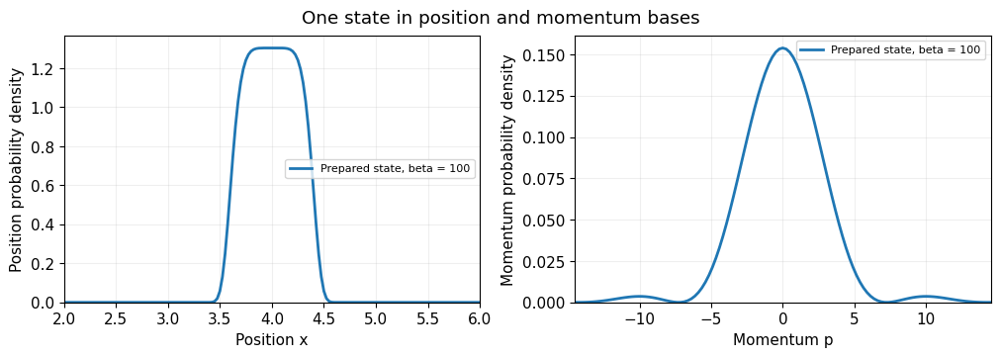

State                                    <x>       <p>        Δx        Δp      Δx Δp
Prepared state, beta = 100           4.00000  -0.00000   0.23335   2.98234   0.695915


In [4]:
# ---------------------------------------------------------------------------
# Exercise 1a: one state, in position space and in momentum space
# ---------------------------------------------------------------------------
# >>> TRY CHANGING: shape_beta (default 100). Try 1 or 10000 and watch Δx and Δp respond.
shape_beta = 100.0          # larger beta -> narrower position distribution
center = 4.0                # x0: where the distribution is centered

uncertainty_grid = FourierGrid(half=12.8, dx=0.025)   # grid from -12.8 to 12.8
x = uncertainty_grid['x']
dx = uncertainty_grid['dx']

# psi(x) = N exp[-beta (x - x0)^6]. Normalize() chooses N so that sum_j |psi_j|^2 = 1.
psi = Normalize(np.exp(-shape_beta * (x - center)**6))

# --- Position statistics ---------------------------------------------------
# |psi_j|^2 is the probability for grid cell j, so each integral becomes a sum:
#   <x>   = integral x   |psi(x)|^2 dx   ->   sum_j x_j   |psi_j|^2
#   <x^2> = integral x^2 |psi(x)|^2 dx   ->   sum_j x_j^2 |psi_j|^2
prob_x = np.abs(psi)**2
mean_x = np.sum(x * prob_x)
mean_x2 = np.sum(x**2 * prob_x)
Delta_x = np.sqrt(mean_x2 - mean_x**2)          # Δx = sqrt(<x^2> - <x>^2)

# --- Momentum statistics ---------------------------------------------------
# Same formulas, but with the momentum-space wavefunction psi~(p), the Fourier
# transform of psi(x). Same state, different representation.
p, psi_p = MomentumRepresentation(uncertainty_grid, psi)
prob_p = np.abs(psi_p)**2
mean_p = np.sum(p * prob_p)
mean_p2 = np.sum(p**2 * prob_p)
Delta_p = np.sqrt(mean_p2 - mean_p**2)          # Δp = sqrt(<p^2> - <p>^2)

print(f"Total probability:  sum|psi(x)|^2 = {prob_x.sum():.6f},   sum|psi~(p)|^2 = {prob_p.sum():.6f}")
print(f"<x> = {mean_x:.5f},   Δx = {Delta_x:.5f}")
print(f"<p> = {mean_p:.5f},   Δp = {Delta_p:.5f}")
print(f"Δx Δp = {Delta_x * Delta_p:.5f}   (the uncertainty principle requires >= 0.5)\n")

# The plotting helper recomputes the same numbers (see StateStatistics) and draws both densities.
pow6state = StateStatistics(uncertainty_grid, psi)
PlotDistributions(pow6state, [f'Prepared state, beta = {shape_beta:g}'],
                  'One state in position and momentum bases', xlim=(center - 2, center + 2))

**Question 1:**

**(a)** Where are the two distributions centered, and how wide are they?

**(b)** The mean momentum is close to zero. Does this mean that a momentum measurement almost always gives zero?

**(c)** Does changing from the position representation to the momentum representation mean the particle has been put into a different state?

<div><img src="https://clark.physics.illinois.edu/246img/AnsStart.svg" width=200 align=left alt="Answer (start)"></img><br></div>

### ANSWER HERE

**(a):** The position probability density function is centered at x = 4 while the momentum probability function is centered at 0. x has a width of ~.5 units while p has a width of ~5 units.

**(b):** This does not mean that a momentum measurement almost always gives a value of zero. You can look at the probability distribution and see the liklihood of a given momentum value; at zero, the chances of measuring p to be zero are ~.15. This means, more often than not, p will be some other value. The expectation value just states what the expected momentum will be after adding up the liklihood of every single position measurement and weighting it by its value. Since this distribution is symetric, the graph is distributed about 1.

**(c):** As both values are determined from the same measurement, these values can't be from different states. Instead, the Fourier transform changes the representation of the same state from position to momentum.

<div><img src="https://clark.physics.illinois.edu/246img/AnsEnd.svg" width=200 align=left alt="Answer (end)"></img><br></div>

### b. Measuring Uncertainty

We now vary $\beta$ from $10^{-4}$ to $10$, keeping the center at $x=4$. Before running, predict how $\Delta x$ and $\Delta p$ will change when $\beta$ decreases and the position distribution becomes broader. Also predict whether the product $\Delta x \Delta p$ must change.

The logarithmic horizontal axis lets you compare changes by factors, rather than by equal increments. Widths and their product are plotted separately. The dashed line marks the uncertainty bound $\Delta x \Delta p = 1/2$.

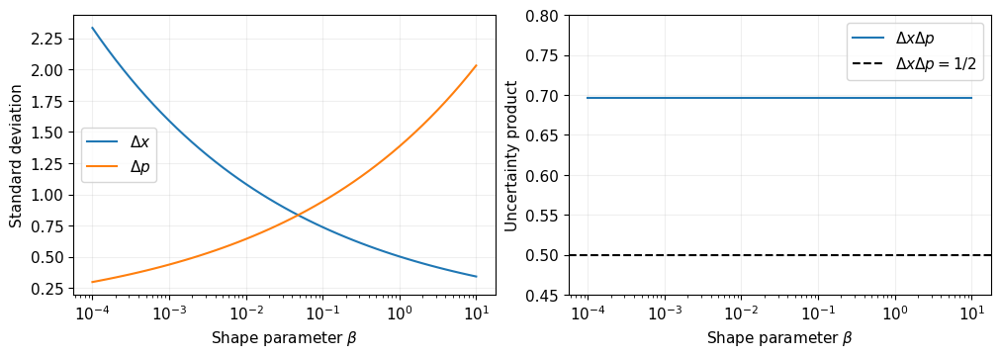

Product range over the sweep: 0.69591508 to 0.69591508


In [5]:
# Recompute the statistics of exp[-beta (x - 4)^6] for 51 values of beta between 1e-4 and 10.
betas = np.logspace(-4, 1, 51)          # equally spaced on a logarithmic axis
width_sweep = UncertaintySweep(uncertainty_grid, betas)
PlotUncertaintySweep(width_sweep)

**Playground: design your own wavefunction.** The sixth-power family above never reached the bound. Is that special to its shape? Compare a Gaussian, a triangle, and two separated Gaussians, then add a wavefunction of your own.

Each entry below is an amplitude as a formula in `x`. The cell normalizes it for you. For example, try `np.exp(-x**4)` or `np.cos(x) * np.exp(-x**2)`. Choose a shape that is nearly zero well before the edges at $x=\pm12.8$, and avoid features narrower than a few grid steps. Predict which shape will have the largest momentum spread, then compare the results.

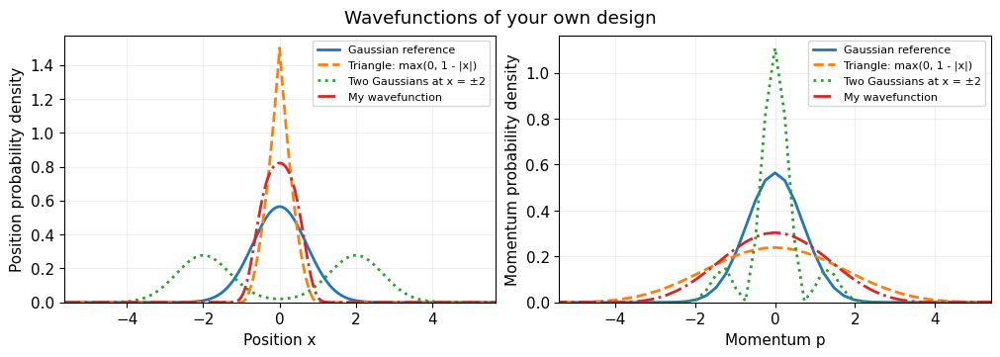

State                                    <x>       <p>        Δx        Δp      Δx Δp
Gaussian reference                  -0.00000  -0.00000   0.70711   0.70711   0.500000
Triangle: max(0, 1 - |x|)           -0.00000  -0.00000   0.31618   1.74134   0.550574
Two Gaussians at x = ±2              0.00000  -0.00000   2.10429   0.65426   1.376754
My wavefunction                     -0.00000  -0.00000   0.41956   1.29692   0.544133


In [6]:
# Playground (Question 2c): any wavefunction you can write as a formula in x.
x = uncertainty_grid['x']
# >>> TRY CHANGING: add entries of the form  '<label>': <formula in x>,
my_wavefunctions = {
    'Gaussian reference':             np.exp(-x**2 / 2),
    'Triangle: max(0, 1 - |x|)':       np.maximum(0, 1 - np.abs(x)),
    'Two Gaussians at x = ±2':         np.exp(-(x - 2)**2 / 2) + np.exp(-(x + 2)**2 / 2),
    'My wavefunction':               np.cos(x) * np.exp(-x**4),
}

if not my_wavefunctions:
    raise ValueError('Keep at least one labelled wavefunction in my_wavefunctions.')

# Normalize each one and put them side by side as columns of one array.
states = np.column_stack([Normalize(f) for f in my_wavefunctions.values()])
my_shapes = StateStatistics(uncertainty_grid, states)
PlotDistributions(my_shapes, list(my_wavefunctions), 'Wavefunctions of your own design')

**Question 2:**

**(a)** Describe what happens to each standard deviation as beta decreases. Does greater certainty about position mean greater certainty about momentum?

**(b)** Does changing beta bring this family of distributions closer to the uncertainty bound?

**(c) (Playground)** Which new wavefunction(s) did you choose? Which of the wavefunctions in the playground, including the one you designed, comes closest to the bound, and which is furthest from it? What feature of a wavefunction's shape seems to make $\Delta p$ large?

<div><img src="https://clark.physics.illinois.edu/246img/AnsStart.svg" width=200 align=left alt="Answer (start)"></img><br></div>

### ANSWER HERE

**(a):** As Beta decreases the standard deviation of position increases and the standard deviation of momentum decreases. This means that as the uncertainty of position increases, the momentum becomes more certain.

**(b):** As beta changes, the uncertainty remains equidistant from the uncertainty bound. It is the same distance the entire time.

**(c):** I chose the wavefunction: np.cos(x) * np.exp(-x**4). Of all the wavefunctions (including the one I designed), the gaussian comes the closest to the uncertainty bound. The function the farthest away is the two gaussians centered at x +- 2. The width of a wavefunction's momentum function determines the size of delta_p; wider peak = more uncertainty.

<div><img src="https://clark.physics.illinois.edu/246img/AnsEnd.svg" width=200 align=left alt="Answer (end)"></img><br></div>

### c. Minimizing Uncertainty

The Gaussian reference reaches the Heisenberg limit; you may have found other examples in the playground. Can a computer search recover that shape? The next cell starts from a different smooth trial shape and adjusts it to reduce the uncertainty product. (Remember that this is a search within just a chosen family of shapes, and is not a full proof of the uncertainty principle).

The quantity minimized is

$J=\Delta x\Delta p+0.01\max(\Delta x,\Delta p).$

The extra term discourages states in which either uncertainty is very large. The output reports both $J$ and the uncertainty product. A Gaussian, $\psi_G(x)=\pi^{-1/4}e^{-x^2/2}$, is plotted for comparison.

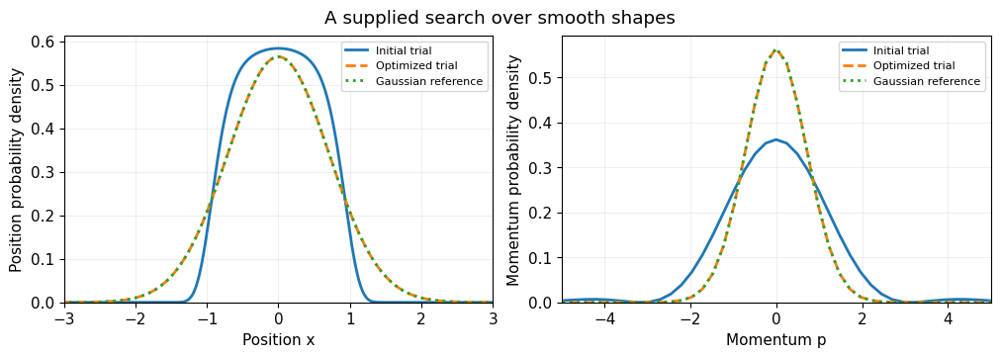

State                                    <x>       <p>        Δx        Δp      Δx Δp
Initial trial                       -0.00000  -0.00000   0.53854   1.22000   0.657014
Optimized trial                     -0.00000  -0.00000   0.70711   0.70711   0.500000
Gaussian reference                  -0.00000  -0.00000   0.70711   0.70711   0.500000
Uncertainty product alone = 0.500000000
Penalized objective J = 0.507071068


In [7]:
optimized = OptimizeUncertainty(uncertainty_grid)
PlotOptimization(optimized)

**Question 3:**

**(a)** How do the optimized position and momentum distributions compare with the initial trial and the Gaussian? How close is the uncertainty product to the Heisenberg limit?

**(b)** Why does the extra term in $J$ discourage states with a very large $\Delta x$ or $\Delta p$?

<div><img src="https://clark.physics.illinois.edu/246img/AnsStart.svg" width=200 align=left alt="Answer (start)"></img><br></div>

### ANSWER HERE

**(a):** After optimizing the position and momentum distributions, the uncertainty product yields a value for delta_x * delta_p of .500000. After the optimization, the distributions became gaussians and rest ontop of the refrence gaussian.

**(b):** The optimizer is trying to find the smallest value possible. As an extra term is added based on the maximal value of delta_x and delta_p, it will add an amount that gets larger with x and p. As the value becomes larger, it is a discouraged solution for the optimizer attempting to find the minimum.

<div><img src="https://clark.physics.illinois.edu/246img/AnsEnd.svg" width=200 align=left alt="Answer (end)"></img><br></div>

### d. Coherent States

A real displacement parameter $\alpha$ gives the zero-mean-momentum coherent state

$\psi_\alpha(x)=\pi^{-1/4}\exp[-(x-\sqrt{2}\alpha)^2/2].$

We first use $\alpha=0.2$. In these oscillator units, a coherent state has the ground-state widths $\Delta x=\Delta p=1/\sqrt{2}$. A displacement changes the means without changing those widths.

### e. Changing the Gaussian width

Compare this with Gaussians $\psi(x)=N e^{-a x^2}$ with other exponents $a$, starting with $a=0.3$ and the ground-state reference $a=0.5$. The reference is itself a coherent state with zero displacement; but the other widths are not coherent-state widths for this oscillator. For such a Gaussian one can show

$\Delta x=\frac{1}{2\sqrt a},\qquad \Delta p=\sqrt a .$

The next cell plots the coherent state together with the Gaussians listed in `gaussian_exponents`, and prints these formula predictions next to the computed values.

The table also lists $\langle H\rangle=\langle x^2\rangle/2+\langle p^2\rangle/2$. This is the average energy each state would have **if it were placed in the harmonic oscillator** $V(x)=x^2/2$ of Exercise 2. You will use it in Questions 4 and 6.

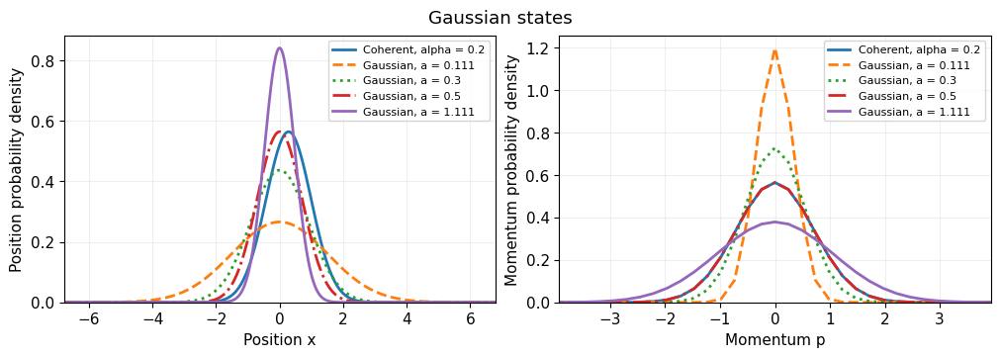

State                                    <x>       <p>        Δx        Δp      Δx Δp  <H> in V=x²/2
Coherent, alpha = 0.2                0.28284  -0.00000   0.70711   0.70711   0.500000        0.54000
Gaussian, a = 0.111                 -0.00000  -0.00000   1.50075   0.33317   0.500000        1.18163
Gaussian, a = 0.3                   -0.00000   0.00000   0.91287   0.54772   0.500000        0.56667
Gaussian, a = 0.5                   -0.00000  -0.00000   0.70711   0.70711   0.500000        0.50000
Gaussian, a = 1.111                  0.00000  -0.00000   0.47437   1.05404   0.500000        0.66801

Formula predictions:
  a = 0.111   Δx = 1/(2 sqrt(a)) = 1.50075    Δp = sqrt(a) = 0.33317
  a = 0.3     Δx = 1/(2 sqrt(a)) = 0.91287    Δp = sqrt(a) = 0.54772
  a = 0.5     Δx = 1/(2 sqrt(a)) = 0.70711    Δp = sqrt(a) = 0.70711
  a = 1.111   Δx = 1/(2 sqrt(a)) = 0.47437    Δp = sqrt(a) = 1.05404


In [8]:
x = uncertainty_grid['x']

# Coherent state from lecture:  psi_alpha(x) = pi^(-1/4) exp[-(x - sqrt(2) alpha)^2 / 2]
alpha_small = 0.2
psi_coherent = np.pi**-0.25 * np.exp(-(x - np.sqrt(2) * alpha_small)**2 / 2)

# Gaussians N exp(-a x^2) with other exponents a.
# >>> TRY CHANGING (Question 4c): ADD exponents to this list (defaults [0.3, 0.5]; use 0.05 <= a <= 4).
gaussian_exponents = [.111, 0.3, 0.5, 1.111]
gaussian_exponents = RealParameters(gaussian_exponents, 'gaussian_exponents',
                                    minimum=0.05, maximum=4, positive=True)
gaussians = [np.exp(-gaussian_a * x**2) for gaussian_a in gaussian_exponents]

labels = [f'Coherent, alpha = {alpha_small:g}'] + [f'Gaussian, a = {gaussian_a:g}' for gaussian_a in gaussian_exponents]
states = np.column_stack([Normalize(f) for f in [psi_coherent] + gaussians])
initial_gaussians = StateStatistics(uncertainty_grid, states)
PlotDistributions(initial_gaussians, labels, 'Gaussian states', show_energy=True)

# Formula check for the Gaussians: Δx = 1/(2 sqrt(a)),  Δp = sqrt(a).
print('\nFormula predictions:')
for gaussian_a in gaussian_exponents:
    print(f'  a = {gaussian_a:<6g}  Δx = 1/(2 sqrt(a)) = {1 / (2 * np.sqrt(gaussian_a)):.5f}    Δp = sqrt(a) = {np.sqrt(gaussian_a):.5f}')

**Question 4:**

**(a)** Do both of the original states (the coherent state and $a=0.3$) reach the Heisenberg uncertainty bound? Are equal numerical values of the two widths necessary to do so? Use the results to explain.

**(b)** Which states have the coherent-state widths for this oscillator? Why is the uncertainty product alone insufficient to identify a coherent state?

**(c) (Playground)** Add at least two more exponents to `gaussian_exponents`, one smaller than 0.3 and one larger than 1, keeping $0.05\le a\le4$. Keep the $a=0.5$ reference in the comparison. Do the computed widths agree with $\Delta x=1/(2\sqrt a)$ and $\Delta p=\sqrt a$? Does the product ever move away from $1/2$? Which Gaussian has the lowest oscillator energy $\langle H\rangle$, and what is special about its exponent?

<div><img src="https://clark.physics.illinois.edu/246img/AnsStart.svg" width=200 align=left alt="Answer (start)"></img><br></div>

### ANSWER HERE

**(a):** Both the coherent state and a = 0.3 reach the heisenberg uncertainty bound. This is as both have a value of sigmax * sigmap ~ .5. the two widths do not have to be equal in value for this to be achieved. For the gaussian with a = .3, the widths are ~.91287 and ~.54772.

**(b):** The two coherent states are a = .2 and a = .5. The uncertainty product is not enough to identify these states as all three states have an uncertainty of .5. Even though a = .3 has an uncertainty of .5, it does not have equal x and widths.



**(c):** Yes these additional states agree with $\Delta x=1/(2\sqrt a)$ and $\Delta p=\sqrt a$. The product of these widths does not ever move away from a value of .5. It is the samee across all gaussians. The a = .5 gaussian has the lowest < H >. This value is special as it is equal to the Heisenberg Uncertainty value. Additionally, any exponents larger or smaller than a = .5 will have a greater value; it is the minimum of < H >.

<div><img src="https://clark.physics.illinois.edu/246img/AnsEnd.svg" width=200 align=left alt="Answer (end)"></img><br></div>

## Exercise 2. Harmonic Oscillator in Real Space

### a. Hamiltonian and Eigenvalues

The harmonic oscillator Hamiltonian is

$\hat H=\frac{\hat p^2}{2m}+\frac12m\omega^2\hat x^2
       =-\frac12\frac{d^2}{dx^2}+\frac12x^2$

in our units. Unlike an infinite square well, the oscillator has no physical walls. Its potential grows continuously away from the center.

The next cell builds this Hamiltonian as a matrix on a grid, exactly as in the Particle in Wells assignment: the kinetic term uses the same finite-difference second derivative, and the potential $V(x)=x^2/2$ is added on the diagonal. The grid runs over $-10\le x\le10$ with $\psi=0$ at both ends. These ends are **not** physical walls. They are a computational boundary, placed far enough out that the low-lying states have decayed to (nearly) zero there. Read the comments in the cell to see each term of $\hat H$ appear.

Before running, recall how the square-well energy gaps changed with state number. Compare that pattern with the first ten oscillator energies and adjacent gaps below. The analytic prediction is $E_n=n+1/2$, starting from $n = 0$.

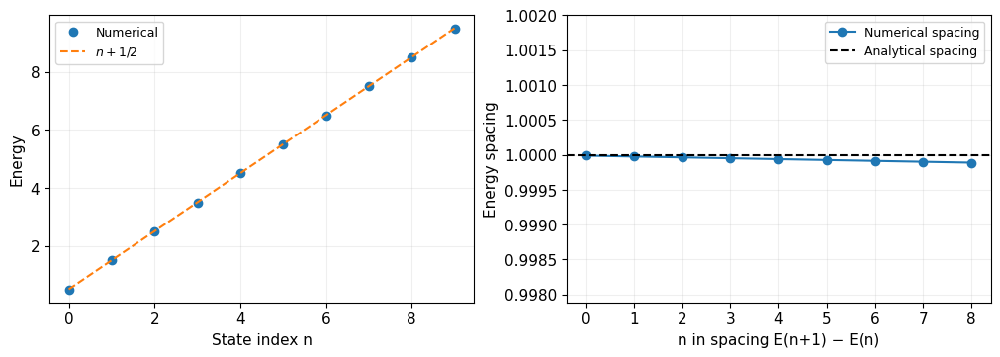

 n     E_n
 0   0.4999969
 1   1.4999844
 2   2.4999594
 3   3.4999219
 4   4.4998719
 5   5.4998094
 6   6.4997344
 7   7.4996469
 8   8.4995469
 9   9.4994343


In [9]:
# ---------------------------------------------------------------------------
# Exercise 2a: build the oscillator Hamiltonian on a grid and diagonalize it
# ---------------------------------------------------------------------------
half = 10.0          # the grid runs from -half to +half, with psi = 0 at the two ends
dx = 0.01            # grid spacing
n_states = 60        # how many of the lowest eigenstates to keep

# Grid points. The two end points are dropped because psi is fixed to 0 there,
# so they are not unknowns.
n_intervals = int(round(2 * half / dx))
x = np.linspace(-half, half, n_intervals + 1)[1:-1]
dx = x[1] - x[0]

# Potential energy:  V(x) = (1/2) m omega^2 x^2  ->  x^2 / 2  in our units.
V = 0.5 * x**2

# Kinetic energy  -(1/2) d^2/dx^2, using the centered second difference
#     d^2 psi/dx^2 at x_j  ≈  (psi_{j+1} - 2 psi_j + psi_{j-1}) / dx^2 .
# Multiplying by -1/2 gives a tridiagonal matrix:
#     +1/dx^2 on the diagonal,   -1/(2 dx^2) on the two neighbouring diagonals.
# V is diagonal in the position basis (it just multiplies psi_j by V(x_j)),
# so H = T + V only changes the diagonal:
H_diagonal = 1 / dx**2 + V
H_off_diagonal = np.full(len(x) - 1, -0.5 / dx**2)

# Solve the matrix eigenvalue problem  H v = E v  for the n_states lowest energies.
# E[n] is E_n, and the column v[:, n] is the grid-normalized eigenstate |n>.
E, v = eigh_tridiagonal(H_diagonal, H_off_diagonal, select='i', select_range=(0, n_states - 1))

# Bundle everything into one dictionary (this also fixes each eigenvector's arbitrary sign).
oscillator = OscillatorModel(x, dx, V, E, v, H_diagonal, H_off_diagonal)
PlotSpectrum(oscillator)

**Playground: other potentials.** How special is the oscillator's equal spacing? The next cell solves $-\tfrac12\psi''+V(x)\psi=E\psi$, with exactly the steps above, for several potentials at once, and compares their energies and spacings.

Try changing a coefficient, add a smooth confining potential of your own, or uncomment the double well and look closely at its lowest levels. A confining potential rises on both sides and keeps these states well away from the ends of the grid. Start with the supplied examples and positive coefficients. A warning about probability near the edges means you should revise your potential before interpreting its levels.

For the three default single wells, compare how the gaps change with level number. The steepness far from the center helps explain the overall trend, but does not determine every low-energy gap: a double well can have closely spaced pairs of levels.

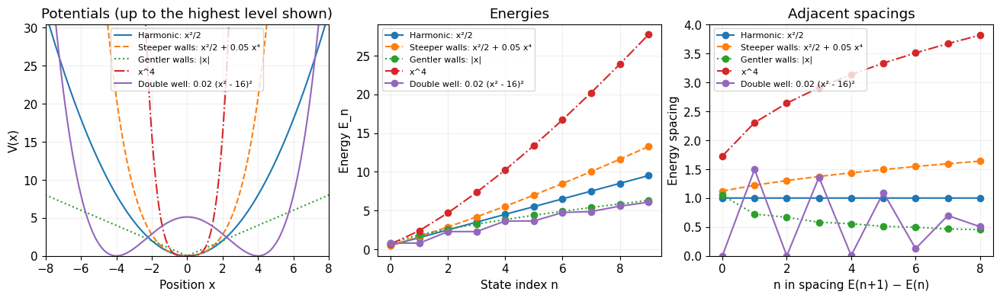

Harmonic: x²/2                     spacings:  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000  1.000
Steeper walls: x²/2 + 0.05 x⁴      spacings:  1.121  1.221  1.302  1.373  1.436  1.492  1.544  1.593  1.638
Gentler walls: |x|                 spacings:  1.047  0.722  0.667  0.581  0.556  0.510  0.495  0.465  0.454
x^4                                spacings:  1.726  2.303  2.639  2.908  3.134  3.332  3.508  3.668  3.815
Double well: 0.02 (x² - 16)²       spacings:  0.000  1.495  0.000  1.359  0.006  1.095  0.126  0.697  0.504


In [10]:
# Playground (Question 5c): compare spectra of different potentials.
# >>> TRY CHANGING: edit or add entries of the form  '<label>': lambda x: <formula in x>,
my_potentials = {
    'Harmonic: x²/2':                    lambda x: 0.5 * x**2,
    'Steeper walls: x²/2 + 0.05 x⁴':     lambda x: 0.5 * x**2 + 0.05 * x**4,
    'Gentler walls: |x|':                lambda x: np.abs(x),
    'x^4'   :                            lambda x: x**4,
    'Double well: 0.02 (x² - 16)²':      lambda x: 0.02 * (x**2 - 16)**2,
}

if not my_potentials:
    raise ValueError('Keep at least one labelled potential in my_potentials.')

# SolveOscillator repeats the steps of the previous cell for any V(x).
# A wider grid (half = 15) leaves room for potentials that rise slowly.
potential_models = {name: SolveOscillator(half=15.0, dx=0.01, n_states=10, potential=V_of_x)
                    for name, V_of_x in my_potentials.items()}
for potential_name, potential_model in potential_models.items():
    near_edge = np.abs(potential_model['x']) > 0.9 * 15.0
    edge_weights = np.sum(abs(potential_model['v'][near_edge])**2, axis=0)
    if edge_weights.max() > 1e-5:
        print(f'WARNING: {potential_name}: a state reaches the grid edges. '
              'Use stronger confinement before interpreting its energies.')
PlotSpectrumComparison(potential_models)

**Question 5:**

**(a)** How do the energy spacings compare with those of the infinite square well? Does the cost of going from n to n+1 increase with n for this oscillator?

**(b)** A classical particle can sit motionless at the potential minimum with zero energy. Why can a normalized quantum state not have both exactly zero position spread and exactly zero momentum spread? Relate this to the nonzero ground-state energy.

**(c) (Playground)** Compare the spacings $E_{n+1}-E_n$ for the potentials in the playground (change or add at least one). For the default single wells, how does the trend in the spacing relate to how steeply the potential rises far from the center? If you try a double well, describe its lowest gaps separately; they need not follow that simple trend. Where would the infinite square well fit into this pattern?

<div><img src="https://clark.physics.illinois.edu/246img/AnsStart.svg" width=200 align=left alt="Answer (start)"></img><br></div>

### ANSWER HERE

**(a):** The energy spacings of the harmonic oscillator do not change with an increase in n. This is different from the infinite square well which increased over every step in the well.

**(b):** Unlike a classical potential well, the minimum value of the groundstate for harmonic oscillator is not zero. Instead, it is 1/2 hbar * w. This means that even at the lowest possible energy state, there is still a nonzero energy. As the energy is nonzero, it will still have the potential to have a real value measured for position and momentum upon observaition resulting in an uncertainty of momentum and position.

**(c):** For potentials less steep than the harmonic oscillator, the energy between spacings decreases. For potentials more steep than the harmonic oscillator, the energy between spacings increases. For the double well, the energy of the lowest gaps will have two spacings at equal energies (one for each bound state on either side of the well).

<div><img src="https://clark.physics.illinois.edu/246img/AnsEnd.svg" width=200 align=left alt="Answer (end)"></img><br></div>

### b. Eigenstates

The analytical eigenfunctions are

$\phi_n(x)=\frac{e^{-x^2/2}H_n(x)}{\pi^{1/4}\sqrt{2^n n!}},$

where $H_n$ is a Hermite polynomial. The next cell evaluates exactly this formula (using SciPy's Hermite polynomials) and plots it together with the numerical eigenvectors from part a. An overall sign change does not change the physical state.

In the next figures, the left column shows **amplitude**, including its sign; the right column shows **probability density**. For a classical particle with energy $E_n$, the turning points satisfy $V(x_t)=E_n$, i.e. $x_t=\pm\sqrt{2E_n}$. Beyond them, $V(x)>E_n$. Shading marks these classically forbidden positions. The cell also adds up $|\psi_j|^2$ over the forbidden grid points.

An energy eigenstate evolves by the phase $e^{-iE_nt}$. Its density is stationary even though its wavefunction changes phase. The reported outside probability is a probability at a given time.

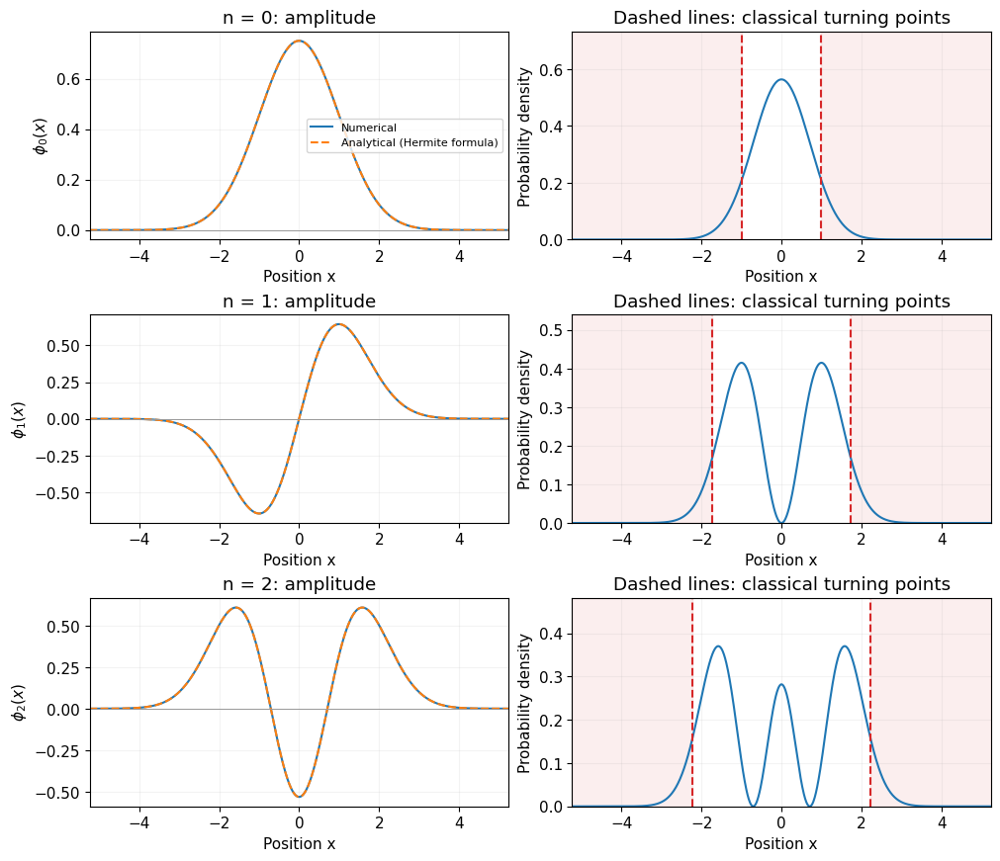

State                                    <x>       <p>        Δx        Δp      Δx Δp
n = 0                               -0.00000  -0.00000   0.70710   0.70711   0.500000
n = 1                                0.00000   0.00000   1.22473   1.22476   1.500000
n = 2                               -0.00000   0.00000   1.58111   1.58116   2.500000

 n    E_n        Turning point |x|     Probability beyond turning points
 0     0.50000       0.999997            0.159379
 1     1.49998       1.732042            0.110611
 2     2.49996       2.236050            0.095386


In [11]:
# ---------------------------------------------------------------------------
# Exercise 2b: eigenstates, analytic formula, and classical turning points
# ---------------------------------------------------------------------------
def HermiteFunction(n, x):
    # phi_n(x) = exp(-x^2/2) H_n(x) / (pi^(1/4) sqrt(2^n n!))
    # eval_hermite(n, x) is the Hermite polynomial H_n(x) used in lecture
    # (H_0 = 1, H_1 = 2x, H_2 = 4x^2 - 2, ...).
    return np.exp(-x**2 / 2) * eval_hermite(n, x) / (np.pi**0.25 * np.sqrt(2.0**n * factorial(n)))

# >>> TRY CHANGING: ADD state labels 0 to 30 (defaults [0, 1, 2], used in Question 6).
n_values = [0, 1, 2]
n_values = StateIndices(n_values, 30, 'n_values')

x = oscillator['x']
phi_analytic = np.column_stack([HermiteFunction(n, x) for n in n_values])

# Classical turning points:  V(x_t) = E_n  ->  x_t^2 / 2 = E_n  ->  x_t = sqrt(2 E_n)
E_n = oscillator['E'][n_values]
x_turn = np.sqrt(2 * E_n)

# Probability of finding the particle beyond the turning points, |x| > x_t:
# add |psi_j|^2 over those grid points (one column per state).
prob = np.abs(oscillator['v'][:, n_values])**2
beyond = np.abs(x)[:, None] > x_turn[None, :]       # True where V(x) > E_n
P_forbidden = np.sum(prob * beyond, axis=0)

stationary = StationaryData(oscillator, n_values, phi_analytic, x_turn, P_forbidden)
PlotStationary(stationary)

**Playground: large $n$ and the classical limit.** A classical oscillator with energy $E$ moves fastest through the center and momentarily stops at the turning points, so it spends most of its time near the turning points. If $x(t)=x_t\sin t$, the fraction of time spent near $x$ gives the classical probability density

$P_{\rm cl}(x)=\frac{1}{\pi\sqrt{x_t^2-x^2}},\qquad |x|<x_t .$

The next cell compares this with $|\phi_n(x)|^2$ for highly excited states. Add at least one more value to `high_n`. Keep $n\le30$ so that the state fits comfortably on the grid.

The quantum curve still has nodes and oscillations. Classical agreement does not mean that the two curves become equal at every point. Compare the probability in intervals containing several oscillations: averaging over those fine features reveals the classical trend. The classical density grows without bound right at a turning point, but its integral over a finite interval is finite; the plot clips the height of these narrow peaks.

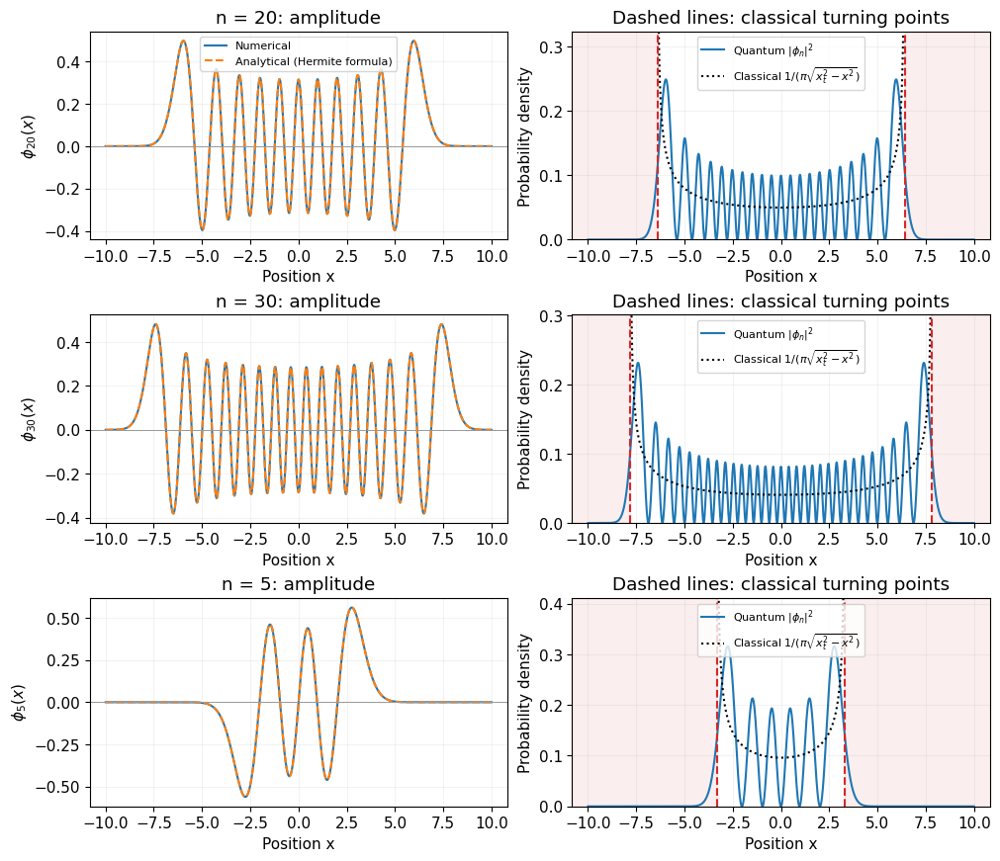

State                                    <x>       <p>        Δx        Δp      Δx Δp
n = 20                               0.00000  -0.00000   4.52711   4.52827  20.500000
n = 30                               0.00000  -0.00000   5.52163   5.52373  30.500000
n = 5                               -0.00000   0.00000   2.34513   2.34529   5.500000

 n    E_n        Turning point |x|     Probability beyond turning points
 20   20.49737       6.402714            0.047892
 30   30.49418       7.809505            0.043399
 5     5.49981       3.316567            0.074448


In [12]:
# Playground (Question 6e): highly excited states versus the classical density.
# >>> TRY CHANGING: ADD values to this list (default [20]; keep n <= 30).
high_n = [20, 30, 5]
high_n = StateIndices(high_n, 30, 'high_n')
x = oscillator['x']

E_high = oscillator['E'][high_n]
x_turn_high = np.sqrt(2 * E_high)                                   # x_t = sqrt(2 E_n)
prob_high = np.abs(oscillator['v'][:, high_n])**2
P_forbidden_high = np.sum(prob_high * (np.abs(x)[:, None] > x_turn_high[None, :]), axis=0)
phi_high = np.column_stack([HermiteFunction(n, x) for n in high_n])

correspondence = StationaryData(oscillator, high_n, phi_high, x_turn_high, P_forbidden_high)
PlotStationary(correspondence, show_classical=True)    # dotted black: 1/(pi sqrt(x_t^2 - x^2))

**Question 6:**

**(a)** If an entire eigenfunction is multiplied by -1, which plotted quantities change and which do not? Explain why this differs from changing the relative sign of only one term in a superposition.

**(b)** Does a stationary density mean that the particle has one definite position? Use the widths and the density plots in your explanation.

**(c)** Is there probability beyond the classical turning points? Why does this not mean that a stationary state is gradually losing its probability or energy?

**(d)** Which of these eigenstates comes closest to the uncertainty bound? Compare its energy with that of the coherent state with $\alpha=0.2$ from Exercise 1d (the $\langle H\rangle$ column of that table). Does minimum uncertainty by itself imply minimum energy?

**(e) (Playground)** Look at the large-$n$ comparison (with at least two values of $n$). Where is the quantum probability density largest, and how does this compare with the classical density? Which features of $|\phi_n(x)|^2$ have no classical counterpart, and how do they change as $n$ grows? Would you expect agreement point by point, or after averaging over several oscillations?

<div><img src="https://clark.physics.illinois.edu/246img/AnsStart.svg" width=200 align=left alt="Answer (start)"></img><br></div>

### ANSWER HERE

**(a):** Multiplying the eigenfunction by -1 flips the amplitudes of the wave. However, the probability density remains the same regardless of the sign. The expected values and the product of widths also remain the same when the eigenfunction is multiplied by 1.

**(b):** A stationary density does not mean that the particle will have one definite position. It has a spread of locations it could be observed within determined by the probability density function. A stationary density function only means the shape of the probability dennsity dunction does not change shape over time.

**(c):** There is a probability for a particle to be observed outside the boundary of the turning points. However, even though the particle can be observed outside this region, that does not mean that the particle is losing energy as the expecation value for energy is an average across the observation of many particles. Additionaly, the particle isn't "leaking" outside of the turning points it just has a probabilty of being found there; the energy of the particle isn't determined until it is measured either inside or outside the well. This is tunneling.

**(d):** The state that has the lowest uncertainty is the n = 0 state. This state has an uncertainty of .5. Minimum uncertainty does not imply that the particle has minimum energy. In problem 1d, the gaussian with a = .2 had minimum uncertainty but had an expectation value for energy greater than .5. This means that simply looking at the uncertainty of these states will not be enough to determine whether or not a particle has minimum energy.   

**(e):** The quantum probability density is greatest near the turning points. This is similar to the classical oscillator as the pobability of finding a classical particle would be greatest near the turning points. However the quantum harmonic oscillator can still tunnel past the "classical" turning points. This tunneling means that a particle can still be measured even past the classical limit. As n increases, the probability of being found beyond the turning poin decreases in probability. While it approaches zero, this does not mean that the probability will ever reach zero; for a given individual point, it can still be measured past this limit; only the average probability changes.

<div><img src="https://clark.physics.illinois.edu/246img/AnsEnd.svg" width=200 align=left alt="Answer (end)"></img><br></div>

### c. Dynamics and Ehrenfest’s Theorem

Use the initial state

$|\Psi(0)\rangle=\sqrt{0.1}|0\rangle+\sqrt{0.25}|1\rangle
                  +i\sqrt{0.65}|2\rangle.$

Each coefficient evolves by its own energy phase:

$\Psi(x,t)=\sum_n c_n\phi_n(x)e^{-iE_nt}.$

The next cell writes this sum out explicitly: each coefficient is multiplied by its phase factor, and the eigenvectors are added up. It saves states from $t=0$ to $40$ at intervals of $0.05$ and prints the energy probabilities $|c_n(t)|^2$ at a few times.

Before running, predict whether the energy probabilities $|c_n(t)|^2$ and the position density must behave in the same way. In the static figures the potential and density have separate vertical axes. An animation, if enabled, adds a line marking the **mean position**, not the trajectory of an individual particle.

Normalization: sum |c_n|^2 = 1.000000
t =   0.0:  |c_n(t)|^2 = 0.1000  0.2500  0.6500
t =  10.0:  |c_n(t)|^2 = 0.1000  0.2500  0.6500
t =  20.0:  |c_n(t)|^2 = 0.1000  0.2500  0.6500
<H> = sum_n |c_n|^2 E_n = 2.04997


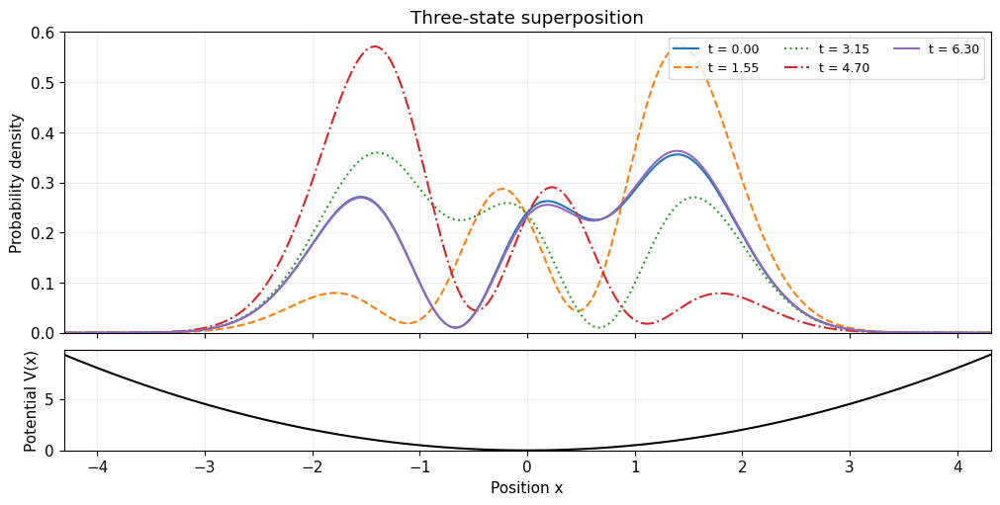

In [13]:
# ---------------------------------------------------------------------------
# Exercise 2c: time evolution of a superposition of energy eigenstates
# ---------------------------------------------------------------------------
times = np.arange(801) * 0.05         # t = 0, 0.05, ..., 40  (about 6.4 periods of 2*pi)

# Initial coefficients c_n = <n|Psi(0)>, for n = 0, 1, 2.
c = np.array([np.sqrt(0.1), np.sqrt(0.25), 1j * np.sqrt(0.65)])
print(f"Normalization: sum |c_n|^2 = {np.sum(np.abs(c)**2):.6f}")

E_n = oscillator['E'][:len(c)]        # energies E_0, E_1, E_2  (≈ 1/2, 3/2, 5/2)
psi_n = oscillator['v'][:, :len(c)]   # eigenstates |0>, |1>, |2> as columns

# Each coefficient just rotates in the complex plane:  c_n(t) = c_n exp(-i E_n t).
# Writing [:, None] and [None, :] makes c_n_t a table with one row per n and
# one column per time.
c_n_t = c[:, None] * np.exp(-1j * E_n[:, None] * times[None, :])

# Psi(x, t) = sum_n c_n(t) psi_n(x). The matrix product does the sum over n
# for every grid point and every time at once; column k of Psi_t is Psi(x, t_k).
Psi_t = psi_n @ c_n_t

# Energy probabilities |c_n(t)|^2 at a few times, and <H> = sum_n |c_n|^2 E_n.
for k in [0, 200, 400]:
    print(f"t = {times[k]:5.1f}:  |c_n(t)|^2 = " + '  '.join(f'{w:.4f}' for w in np.abs(c_n_t[:, k])**2))
print(f"<H> = sum_n |c_n|^2 E_n = {np.sum(np.abs(c)**2 * E_n):.5f}")

superposition = EvolutionResults(oscillator, times, Psi_t, label='Three-state superposition')
PlotSnapshots(superposition)
if SHOW_ANIMATIONS:
    display(AnimateDensity(superposition))

**Question 7:**

**(a)** Describe a change in the density’s shape as it evolves. Does it look like a fixed shape that is simply being translated? Identify the snapshots you compared.

**(b)** Do the probabilities for the three possible energy outcomes change with time? Explain using the phase factors, and predict whether the mean energy changes even when the position density does.

<div><img src="https://clark.physics.illinois.edu/246img/AnsStart.svg" width=200 align=left alt="Answer (start)"></img><br></div>

### ANSWER HERE

**(a):** The density's shape changes as it evolves. At t = 0, the density looks like two hills where the right hill has two peaks. However, at t = 24, there are two distinct single peaked hills and then a very small third hill. The probability density is not some fixed shape being translated through time.  

**(b):** The probablities of the three possible energy outcomes do not change with time. They remain the exact same as their coefficients across t = 0, 10, and 20. This makes sense as the time component of the wavefunction is dropped when the absolute value and sqr is taken. The phase factor of e^i(theta)t is multiplied against e^-i(theta)t canceling each other out. The mean energy should remain the same as well. As |cn|^2 isn't changing and the engeries are eigenstates (and are static values) the expected energy won't change as < H > doesn't depend on time.

<div><img src="https://clark.physics.illinois.edu/246img/AnsEnd.svg" width=200 align=left alt="Answer (end)"></img><br></div>

For this oscillator, Ehrenfest’s theorem gives

$\frac{d\langle x\rangle}{dt}=\langle p\rangle,\qquad
\frac{d\langle p\rangle}{dt}=-\langle V'(x)\rangle=-\langle x\rangle.$

The next plots compare $\langle p\rangle$ with $d\langle x\rangle/dt$, and $d\langle p\rangle/dt$ with $-\langle x\rangle$. They also show momentum versus position, using the expectation values at each time.

For comparison, a classical oscillator starting at the same initial position and momentum has

$x_{\rm cl}(t)=\langle x\rangle_0\cos t+\langle p\rangle_0\sin t,\quad
p_{\rm cl}(t)=\langle p\rangle_0\cos t-\langle x\rangle_0\sin t.$

The energy and width plots show whether the mean energy and the spreads in position and momentum change during the motion.

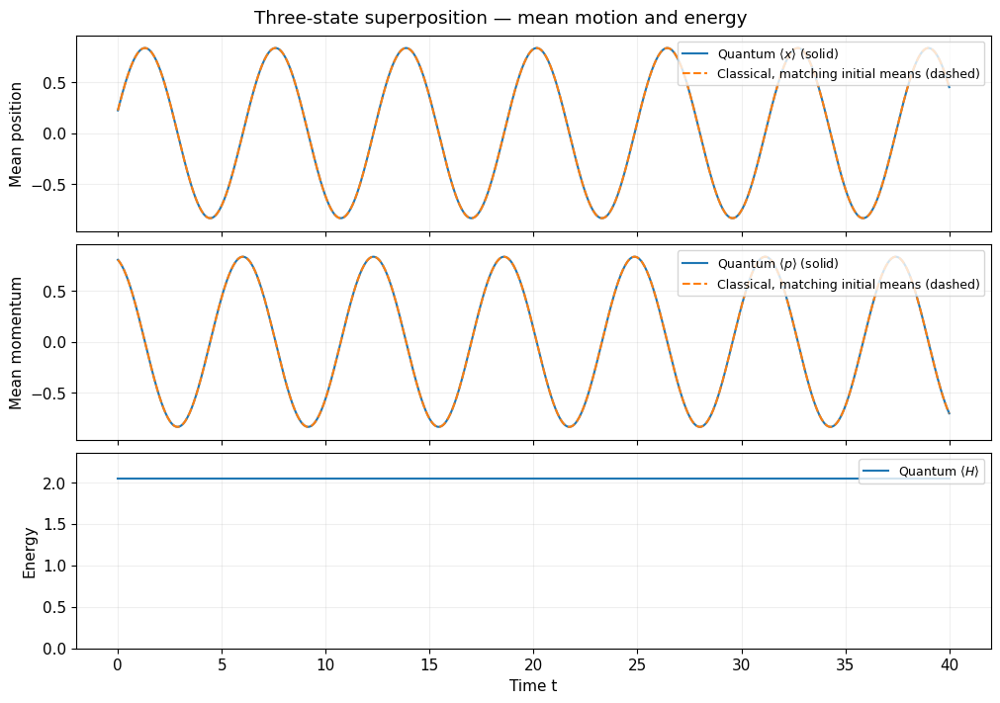

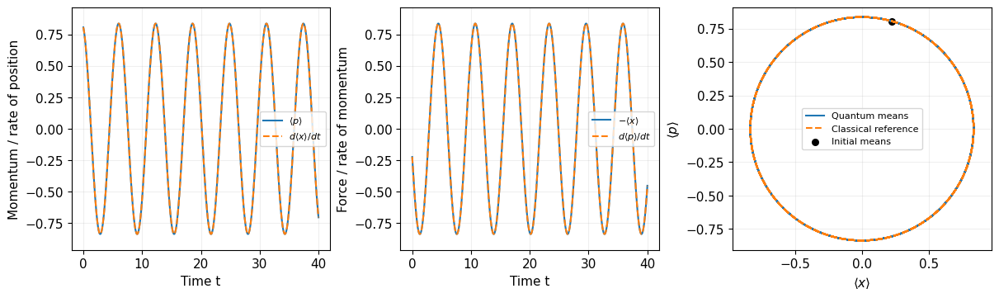

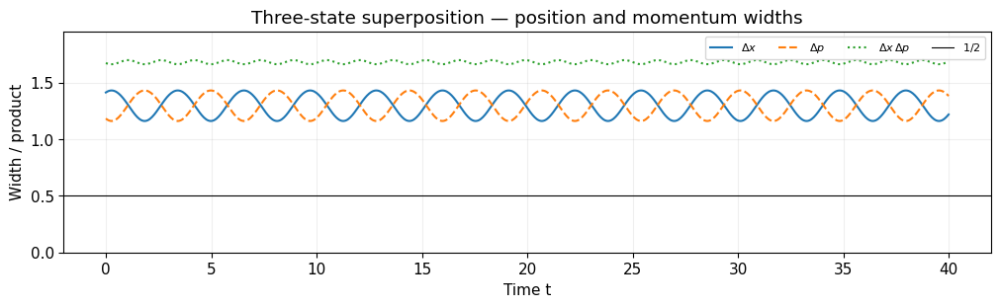

In [14]:
# Means, Ehrenfest checks, energy, and widths for the three-state superposition.
# <H>(t) is computed directly from Psi(x, t) as sum_j Psi_j^* (H Psi)_j, independently of the c_n.
PlotDynamics(superposition)

**Playground: your own superpositions.** Each entry in `my_superpositions` is a list $[c_0,c_1,c_2,\ldots]$. The entry's position tells you its energy level: `[1, 0, 1]` includes levels 0 and 2 but no level 1. The cell normalizes your coefficients, so you do not need to divide by $\sqrt2$ yourself. Keep the two supplied comparisons for Question 8(d). You may add your own list, using levels 0–30.

Python writes the imaginary unit $i$ as `1j`. Thus `[1, 1]`, `[1, -1]`, and `[1, 1j]` have the same energy probabilities, but different **relative phases** between the two contributions. Amplitudes add before we take their absolute square, so their relative phase can change how they reinforce or cancel each other in position space. This is interference.

**Predict first:** must the same energy probabilities give the same position density or the same initial motion? What if both coefficients, rather than just one, change sign?

The first cell keeps the adjacent/nonadjacent-level comparison. The guided cell that follows varies only the relative phase. For Question 8(e), **either add a custom superposition here or add a new phase there**; you do not need to do both.

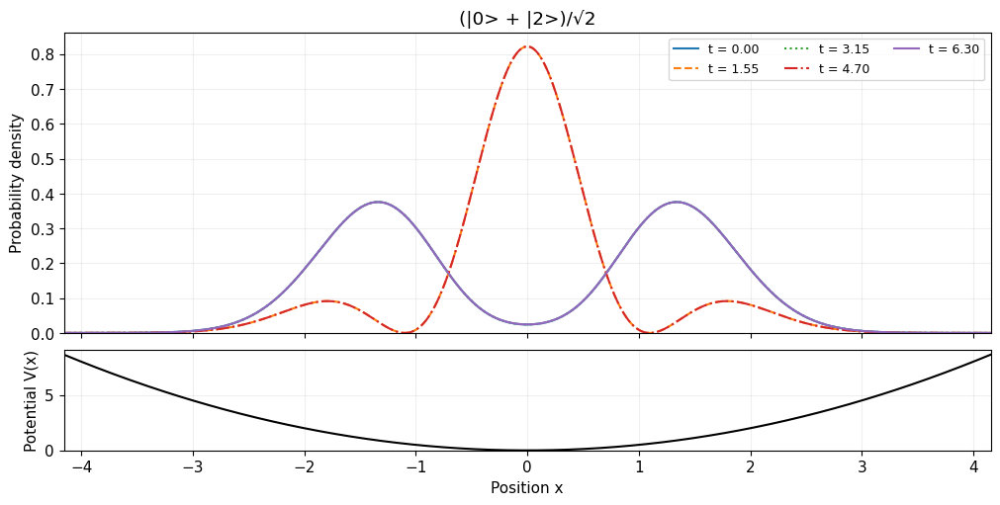

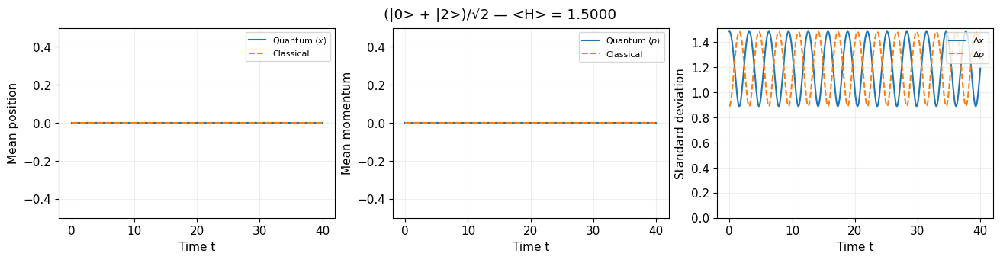

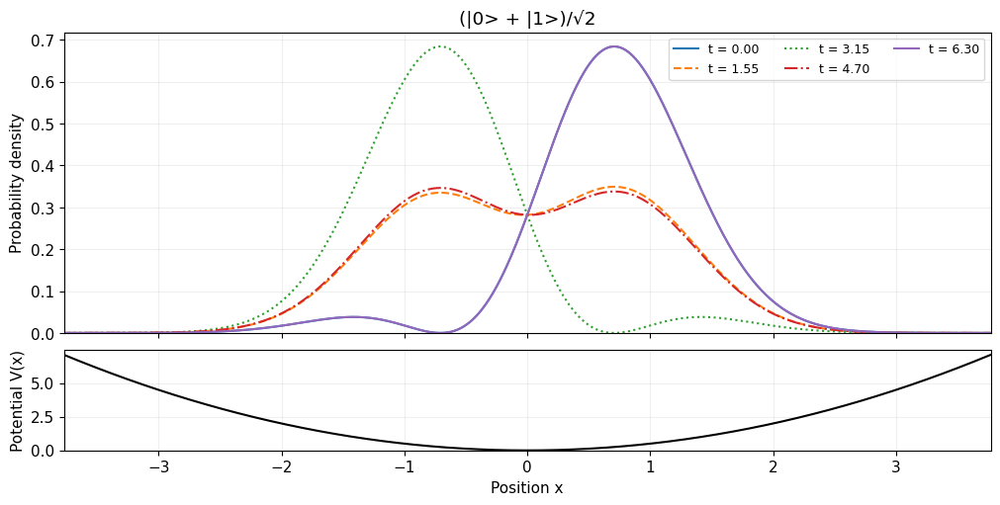

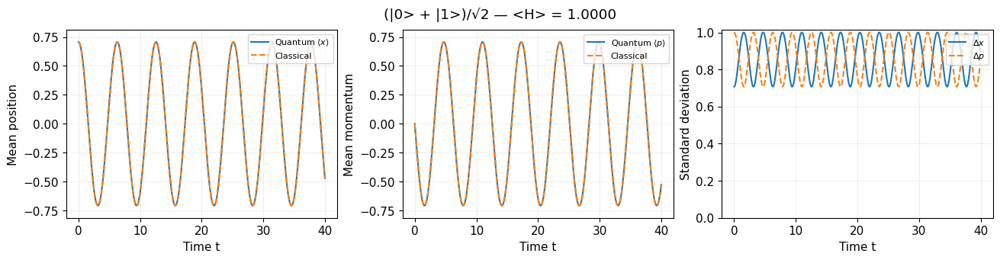

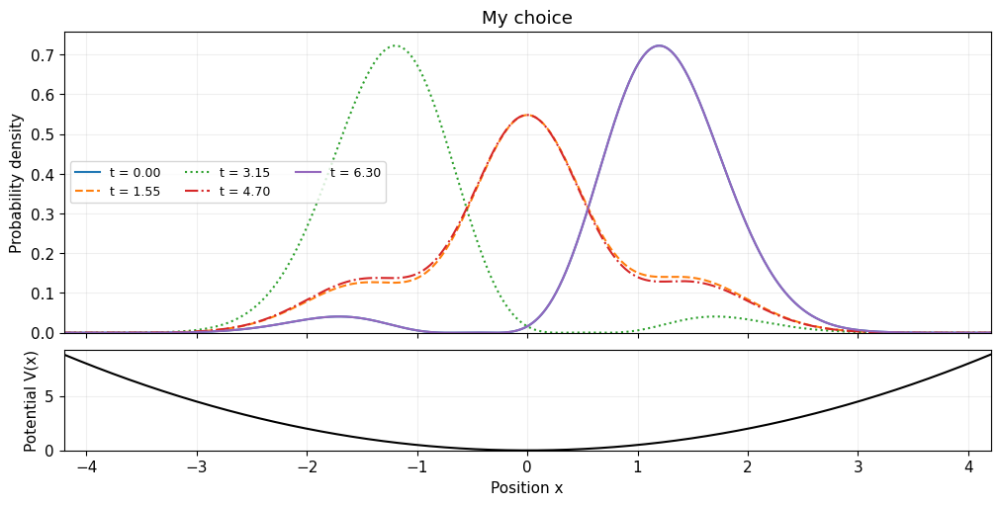

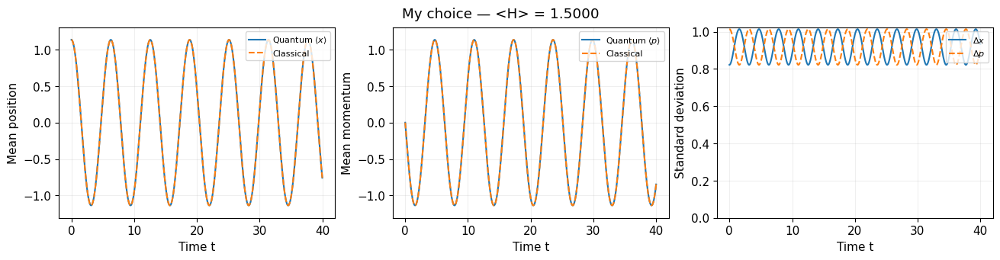

In [15]:
# Playground (Question 8d–e): keep the defaults; optionally add a custom state.
# >>> TRY CHANGING: ADD 'label': [c_0, c_1, c_2, ...], using levels 0 to 30.
my_superpositions = {
    '(|0> + |2>)/√2': [1, 0, 1],
    '(|0> + |1>)/√2': [1, 1],
     'My choice':    [1, 1, 1],
}
if not my_superpositions:
    raise ValueError('Keep the two supplied comparisons in my_superpositions.')
superposition_runs = {}
for state_label, state_coefficients in my_superpositions.items():
    state_result = EvolveCoefficients(oscillator, state_coefficients, times, state_label)
    superposition_runs[state_label] = state_result
    PlotSnapshots(state_result)
    PlotMeansAndWidths(state_result)

**Guided comparison: same energy probabilities, different motion.** We use
$|\psi_\theta\rangle=(|0\rangle+e^{i\theta}|1\rangle)/\sqrt2$.
Here $e^{i\theta}$ changes the relative phase without changing the magnitude of either coefficient. The values $\theta=0,\pi/2,\pi$ give the second coefficient $1,i,-1$. Enter angles in radians; for example, `np.pi / 4` means $\pi/4$.

An **overall phase** multiplies the entire state. Multiplying both coefficients by $-1$ changes the amplitudes' signs, but leaves all probabilities and mean values unchanged. Compare the separate `psi` and `-psi` plots with the relative-phase plots. The table helps distinguish curves that overlap. One oscillator period is $2\pi$ in our units; the finite-grid results approximate that period.

Relative phase (radians)   P(n=0)   P(n=1)   <x>(0)    <p>(0)
                  0.0000   0.5000   0.5000    0.7071    0.0000
                  1.5708   0.5000   0.5000    0.0000    0.7071
                  3.1416   0.5000   0.5000   -0.7071    0.0000


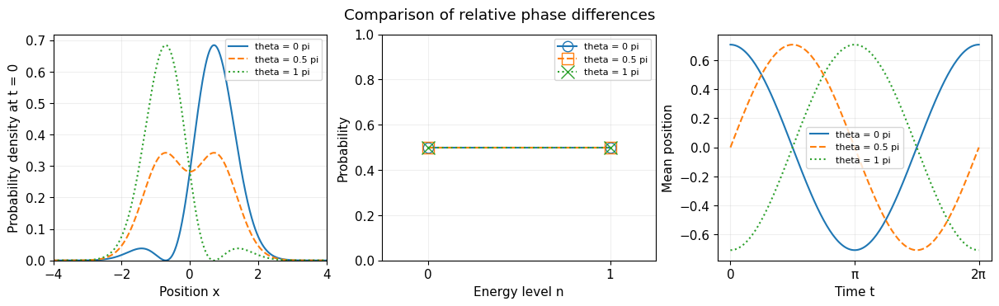

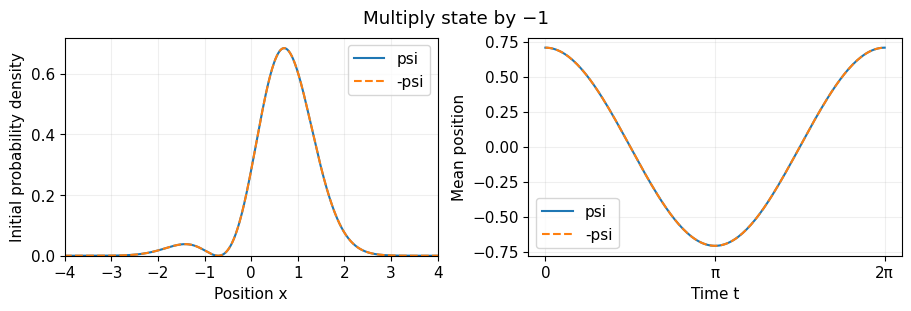

Overall minus sign: energy probabilities remain [0.5, 0.5].
Largest density difference over the full period: 0.0e+00


In [16]:
# Playground (Question 8e): add a phase OR add a custom state in the preceding cell.
# >>> TRY CHANGING: ADD an angle in radians (defaults [0, pi/2, pi]).
relative_phases = [0, np.pi / 2, np.pi]
phase_comparison = PhaseComparison(oscillator, relative_phases)
PlotPhaseComparison(phase_comparison)

**Question 8:**

**(a)** Choose a maximum or minimum of the mean-position curve. What is the mean momentum there, and what is the direction of the mean restoring force? Relate these observations to both Ehrenfest equations.

**(b)** Compare the quantum means with the matching classical curves and their position–momentum orbit. Does agreement establish that the complete quantum distribution moves rigidly? Use the snapshots in Exercise 2c as evidence.

**(c)** Does the quantum mean-position curve $\langle x\rangle(t)$ (the solid line in the top panel) describe the path of a particle that is measured continuously? Explain what the expectation value represents in this calculation, and check your energy prediction from Question 7.

**(d) (Playground)** For which of $(|0\rangle+|2\rangle)/\sqrt2$ and $(|0\rangle+|1\rangle)/\sqrt2$ does $\langle x\rangle$ oscillate, and for which does it stay at zero even though the density changes? With what angular frequency does each density repeat? Explain using the energy differences $E_m-E_n$ that appear in $|\Psi(x,t)|^2$.

**(e) (Playground)** Record your prediction from the playground introduction. For $\theta=0,\pi/2,\pi$, compare the energy probabilities, initial position densities, and mean-position curves. Does the relative phase change the period or where the motion starts? How does this differ from multiplying the whole state by $-1$ (Question 6a)? Report the additional phase **or** custom superposition you tried, and describe one observation using a labelled plot or numerical result.

<div><img src="https://clark.physics.illinois.edu/246img/AnsStart.svg" width=200 align=left alt="Answer (start)"></img><br></div>

### ANSWER HERE

**(a):** For the mean position graph, at a maximum the mean momentum is 0. The restoring force is pointed towards the direction of < x >. This can be related to Ehrenfest's theorem as it states that d < p > /dt = - < V' > = - < x >. < p > = m < v > the derivative of < p > would be m < a >. Since the acceleration is in the - < x > direction, this agrees with the orientation of the restoring force.

**(b):** The classical harmonic oscillator perfectly agrees with the mean position and mean momentum harmonic oscillator. However, this does not mean that the quantum distribution moves rigidly. It is only the mean values that line up; an individual particle's position and momentum will still be dependendant on the probabilities associated with a measurement. It is only the collection of measured positions and momentums that agrees.

**(c):** The mean position graph does not represent a particle that is being measured continuously. A particle who is measured will take on a position and momentum value based on the probability of the probability density function. Once observed however, it will continue to have the initially measured value upon further observations. This curve rather, is the average measurements of an assembly of particles. This matches my predictions that the average energy will remain the same as it is the average across many observations.

**(d):** state (|0 > + | 1 >)/srt(2) oscillates in < x > while state (|0 > + | 2 >)/srt(2) has a nonchanging < x >. It has an angular frequency of ~2pi/7.5. The rate of oscillation is (Em - En)/hbar. The reason (|0 > + | 2 >)/srt(2) doesn't oscillate is as state 2 has an i in the coeffiecient. This prevents this term's imaginary time exponential to become non-imaginary. This then doesn't create the e^-i * e^-i that can be reduced to a cosine with euler's formula.

**(e):** Prediction: The same energy probabilities don't need to give the same initial conditions. Multistates can oscillate in time, changing direction of energy will change oscillation even if magnitude is the same. For coefficients the position should stay the same -> will get squared and cancel out to be the same value.

Changing the phase angle does not change the period of the oscilations. However, the mean position and the initial position densities do change depending on theta. This is different from multiplying the whole state by -1 as the mean position and initial position density remain the exact same. I added a three state wave (0, 1, and 2). This wave oscillates with the same frequency of the state 0 + 1 wave; this makes sense as the imaginary time portion cancels out of the exponential of 2, just like in the 0 + 2 state.


<div><img src="https://clark.physics.illinois.edu/246img/AnsEnd.svg" width=200 align=left alt="Answer (end)"></img><br></div>

### d. Coherent States

Now begin with the coherent state

$\psi(x,0)=\pi^{-1/4}e^{-(x-\sqrt{2}\,\alpha)^2/2},\qquad \alpha=3 .$

This has initial mean position $3\sqrt{2}$ and initial mean momentum zero. We repeat the time evolution and compare the position and momentum with a classical oscillator starting at the same position, at rest.

This time the coefficients are not given; the cell computes them by projecting the initial state onto each eigenstate,

$c_n=\langle n|\psi(0)\rangle=\int\phi_n^*(x)\,\psi(x,0)\,dx ,$

and then evolves them exactly as in part c. It also plots the probabilities $|c_n|^2$ and compares them with the Poisson distribution $|c_n|^2=e^{-\alpha^2}\alpha^{2n}/n!$ expected for a coherent state. (Optional: once you have answered Question 9, try other values of `coherent_alpha` between 0 and 4.)

Predict how this state’s shape and widths will compare with those of the three-state superposition. Then inspect the snapshots, width curves, and classical comparison.

sum |c_n|^2           = 1.00000000
<n> = sum n |c_n|^2   = 9.00062      (alpha^2 = 9.00000)
<H> = sum E_n |c_n|^2 = 9.50000


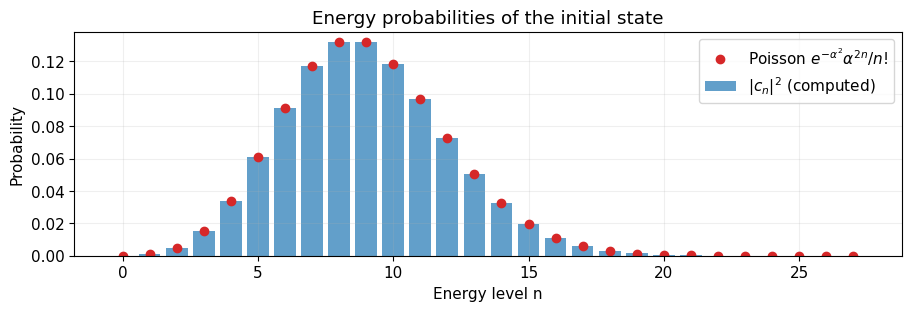

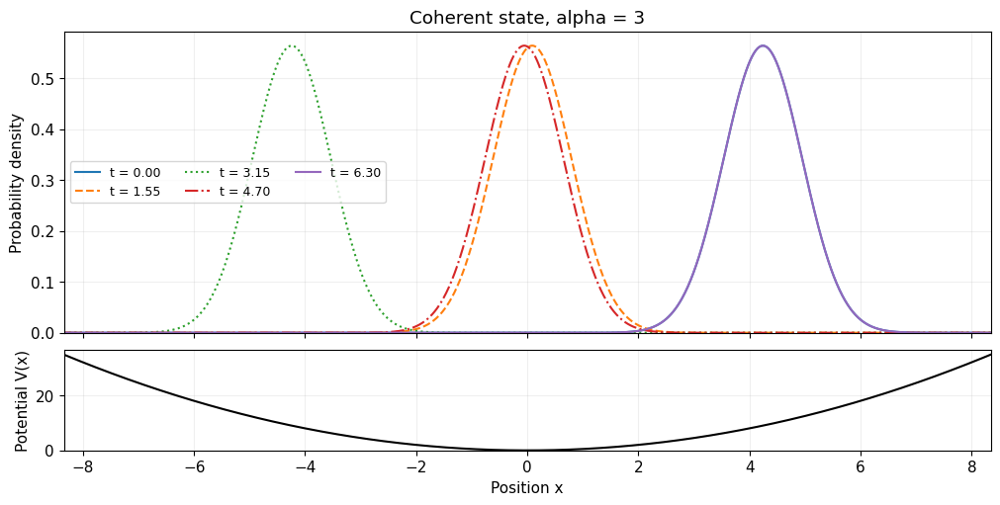

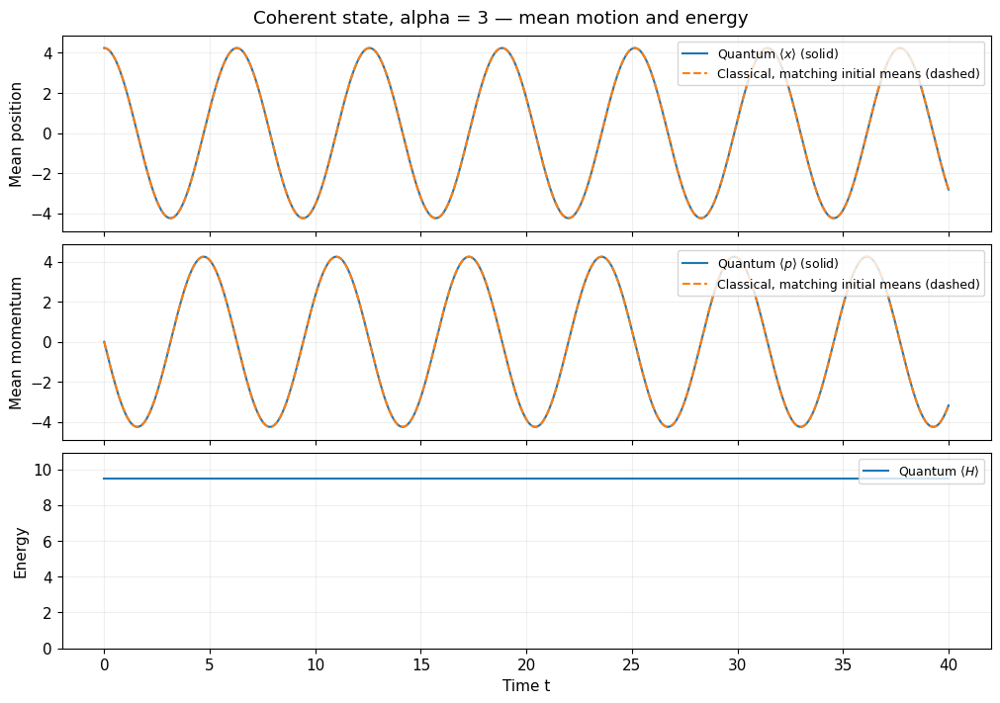

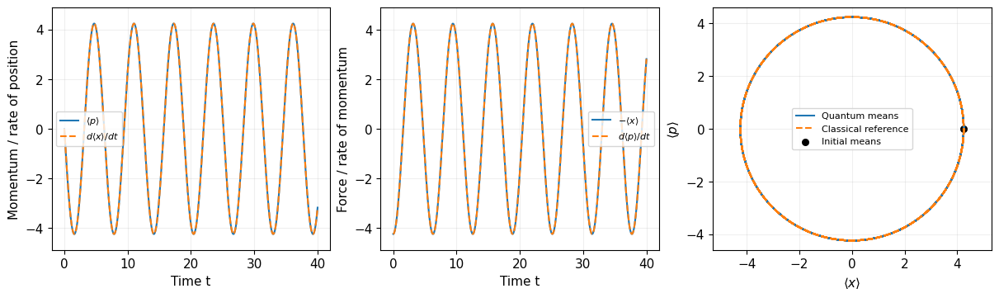

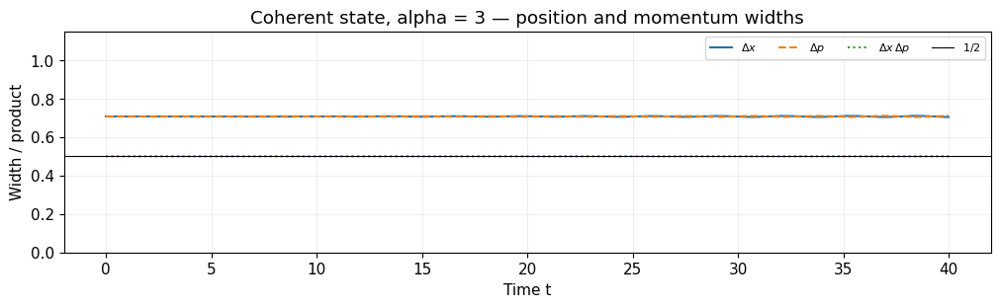

In [17]:
# ---------------------------------------------------------------------------
# Exercise 2d: a coherent state, expanded in energy eigenstates and evolved
# ---------------------------------------------------------------------------
# >>> TRY CHANGING (optional): coherent_alpha (default 3.0; keep 0 <= alpha <= 4).
coherent_alpha = 3.0

x, E, v = oscillator['x'], oscillator['E'], oscillator['v']

# psi(x, 0) = pi^(-1/4) exp[-(x - sqrt(2) alpha)^2 / 2]   (Normalize supplies the sqrt(dx) factor)
psi0 = Normalize(np.pi**-0.25 * np.exp(-(x - np.sqrt(2) * coherent_alpha)**2 / 2))

# Expand in energy eigenstates:  c_n = <n|psi(0)> = sum_j psi_n(x_j)^* psi0(x_j),
# the grid version of integral phi_n(x)^* psi(x, 0) dx.  v.conj().T @ psi0 does
# this for every n at once (row n of v.conj().T is <n|).
c = v.conj().T @ psi0
CheckExpansion(oscillator, psi0, c)   # stops with an explanation if 60 states are not enough

n = np.arange(len(c))
print(f"sum |c_n|^2           = {np.sum(np.abs(c)**2):.8f}")
print(f"<n> = sum n |c_n|^2   = {np.sum(n * np.abs(c)**2):.5f}      (alpha^2 = {coherent_alpha**2:.5f})")
print(f"<H> = sum E_n |c_n|^2 = {np.sum(E * np.abs(c)**2):.5f}")
PlotCoefficients(c, alpha=coherent_alpha)

# Time evolution, exactly as in Exercise 2c:  Psi(x, t) = sum_n c_n psi_n(x) exp(-i E_n t)
Psi_t = v @ (c[:, None] * np.exp(-1j * E[:, None] * times[None, :]))
coherent = EvolutionResults(oscillator, times, Psi_t, label=f'Coherent state, alpha = {coherent_alpha:g}')
PlotSnapshots(coherent)
PlotDynamics(coherent)
if SHOW_ANIMATIONS:
    display(AnimateDensity(coherent))

**Playground: squeezed states.** What if the initial Gaussian does not have the right width for this oscillator? The next cell starts Gaussians

$\psi(x,0)=N e^{-a(x-x_0)^2},\qquad x_0=2,$

with the exponents listed in `squeeze_exponents`. The value $a=1/2$ is a coherent state. A Gaussian with $a>1/2$ is narrower in position than the ground state, and one with $a<1/2$ is wider; such states are called *squeezed*. Add at least one value $a<1/2$ to the list, keeping $0.2\le a\le2$.

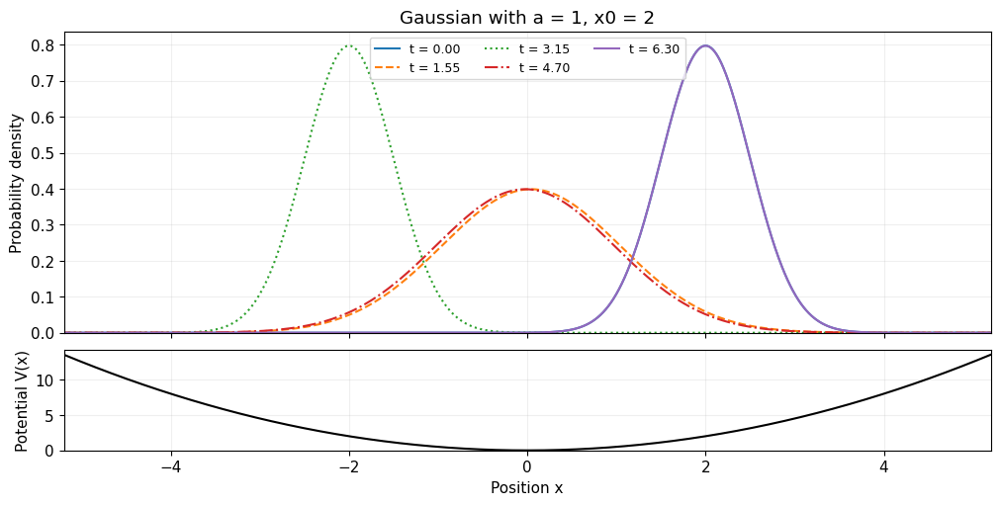

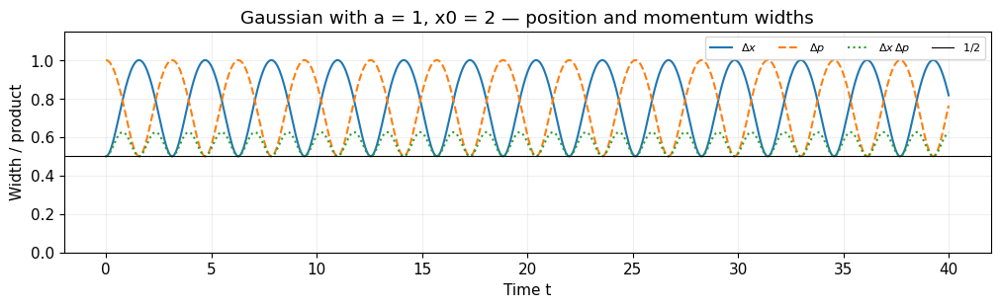

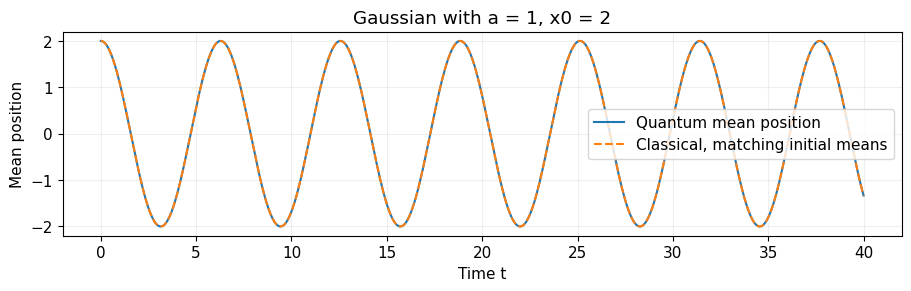

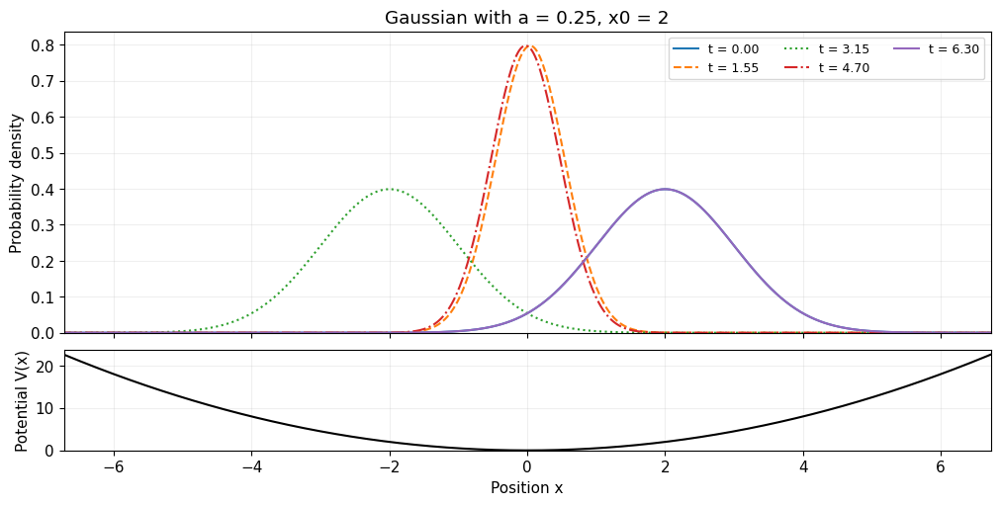

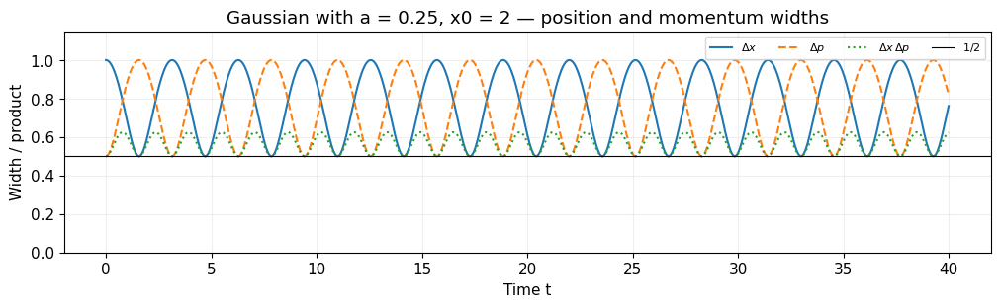

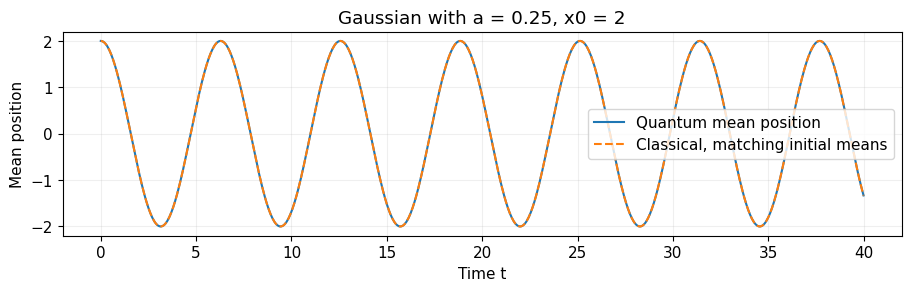

In [18]:
# Playground (Question 9d): Gaussians that are narrower or wider than the ground state.
# >>> TRY CHANGING: ADD exponents to this list (default [1.0]; keep 0.2 <= a <= 2).
squeeze_exponents = [1.0, .25]
start_position = 2.0
squeeze_exponents = RealParameters(squeeze_exponents, 'squeeze_exponents',
                                   minimum=0.2, maximum=2, positive=True)

x, E, v = oscillator['x'], oscillator['E'], oscillator['v']
squeezed_runs = {}
for squeeze_a in squeeze_exponents:
    psi0 = Normalize(np.exp(-squeeze_a * (x - start_position)**2))    # N exp[-a (x - x0)^2]
    c = v.conj().T @ psi0                                      # c_n = <n|psi(0)>
    CheckExpansion(oscillator, psi0, c)
    Psi_t = v @ (c[:, None] * np.exp(-1j * E[:, None] * times[None, :]))
    result = EvolutionResults(oscillator, times, Psi_t, label=f'Gaussian with a = {squeeze_a:g}, x0 = {start_position:g}')
    PlotSnapshots(result)
    PlotWidths(result)
    PlotSqueezedMean(result)
    squeezed_runs[float(squeeze_a)] = result

**Question 9:**

**(a)** Compare the coherent-state snapshots and widths with the three-state superposition. What additional feature, beyond classical motion of the means, makes the coherent state resemble a localized classical oscillator?

**(b)** Where is the mean momentum largest in magnitude, and where does it vanish? Relate this to the mean position and the position–momentum orbit. Why does the nonzero width still matter for individual measurements?

**(c)** Compare the computed $|c_n|^2$ with the Poisson distribution. How are the printed $\langle n\rangle$ and $\langle H\rangle$ related to $\alpha$? Using $E_n=n+1/2$, explain why $\langle H\rangle=\langle n\rangle+1/2$.

**(d) (Playground)** Run the squeezed-state cell with $a=1$ and at least one value $a<1/2$. How do $\Delta x$ and $\Delta p$ behave in time, and with what angular frequency do they oscillate? Is $\Delta x\,\Delta p=1/2$ at all times? Does the mean position still follow the classical oscillator?

<div><img src="https://clark.physics.illinois.edu/246img/AnsStart.svg" width=200 align=left alt="Answer (start)"></img><br></div>

### ANSWER HERE

**(a):** Another similarity between the classical oscillator and the coherent state is that the coherent state's width of both x and p do not change in time. For the three-state superposition, this value was oscillaitng.

**(b):** The mean momentum is largest when the mean position is at zero. It goes to zero when mean position is at a maximum or minimum. The nonzero widths still matter for an individual measurement as this points to the differences among individual masurements; when a measurement is made it can take on any position eigenstate based upon its probabilities. This means that indivdual measurements will yield to a spread of positions. Thus, when you make a measurement, there will be a spread of potential points about the mean.

**(c):** Alpha sets the coefficents that affect the shape of the Poisson equation. As the probabilities follow the Poisson equation, the measurements will be distributed according to alpha. The expected value for < n > is: e^-a^2 * a^2n / n!. Similarly, as the probabilities are affected by this Poisson distribution, the expected energy will shift based on these probabilities. Since the steps are evenly distrbuted, the distrbution of energies is already normalized. This means that if you take < n > it will be the same as adding up all the coeffcients energies.

**(d):** deltaxdeltap oscillates in time with an angular frequency of about 2pi / 3.5. deltax * deltap is not .5 the entire time. It will go to a maximum of ~.61 before coming back down to .5. This repeats the entire time. The mean value however still follows the classical harmonic oscillator the entire time.

<div><img src="https://clark.physics.illinois.edu/246img/AnsEnd.svg" width=200 align=left alt="Answer (end)"></img><br></div>

## Exercise 3. Raising and Lowering Operators

### a. Raising and Lowering Operators

For the harmonic oscillator, it is useful to define the raising and lowering operators. In our units,

$a=\frac{X+iP}{\sqrt{2}},\qquad a^\dagger=\frac{X-iP}{\sqrt{2}}.$

The dagger means conjugate transpose. The next cell builds $X$, $P$, $a$ and $a^\dagger$ as matrices on the grid of Exercise 2, with comments connecting each line to its formula. It also checks that the conjugate transpose of $a$ is the same matrix as the formula for $a^\dagger$.

The images show the first ten rows and columns of $a$ and $a^\dagger$ in the position basis. The diagonal entries come from $X$, and the neighbouring entries come from $P$. Each column is an input grid point and each row is an output grid point.

Largest difference between a.conj().T and (X - iP)/sqrt(2): 0.0e+00


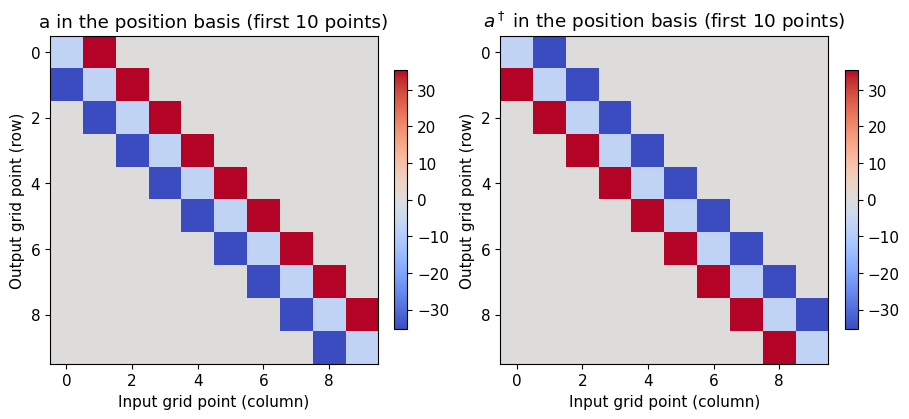

In [19]:
# ---------------------------------------------------------------------------
# Exercise 3a: X, P, a, and a† as matrices on the position grid
# ---------------------------------------------------------------------------
x, dx = oscillator['x'], oscillator['dx']
N = len(x)

# Position operator: multiplying psi(x) by x. In the position basis this is a
# diagonal matrix with the grid positions x_j on the diagonal.
X = diags(x, format='csr')

# Momentum operator  P = -i d/dx, using the centered first difference
#     (P psi)_j = -i (psi_{j+1} - psi_{j-1}) / (2 dx).
# Row j therefore has  -i/(2 dx)  in column j+1 (offset +1, above the diagonal)
# and  +i/(2 dx)  in column j-1 (offset -1, below the diagonal).
P = diags([np.full(N - 1, +1j / (2 * dx)), np.full(N - 1, -1j / (2 * dx))],
          offsets=[-1, +1], format='csr')

# Ladder operators  a = (X + iP)/sqrt(2)  and  a† = conjugate transpose of a.
a = (X + 1j * P) / np.sqrt(2)
adag = a.conj().T

# Check: a† built from its own formula (X - iP)/sqrt(2) is the same matrix.
adag_formula = (X - 1j * P) / np.sqrt(2)
print(f"Largest difference between a.conj().T and (X - iP)/sqrt(2): {abs(adag - adag_formula).max():.1e}")

# Apply a and a† to the first ten eigenstates (used in parts b to d).
ladder = LadderData(oscillator, a, adag, n_show=10)
PlotPositionOperators(a, adag)

### b. Testing the Raising and Lowering Operators

We expect $a^\dagger|n\rangle=\sqrt{n+1}|n+1\rangle$ and $a|n\rangle=\sqrt{n}|n-1\rangle$.

Let’s check these by plotting $a^\dagger|3\rangle$ alongside $\sqrt{4}|4\rangle$, and $a|5\rangle$ alongside $\sqrt{5}|4\rangle$. We also check what happens when the operators act on the ground state. (Optional: change `n_raise` and `n_lower` to test other states, but use the defaults for Question 10.)

The plotted outputs have not been normalized after applying the operators. Check the printed norms as well as the shapes: the small residual from lowering the ground state should be compared with zero.

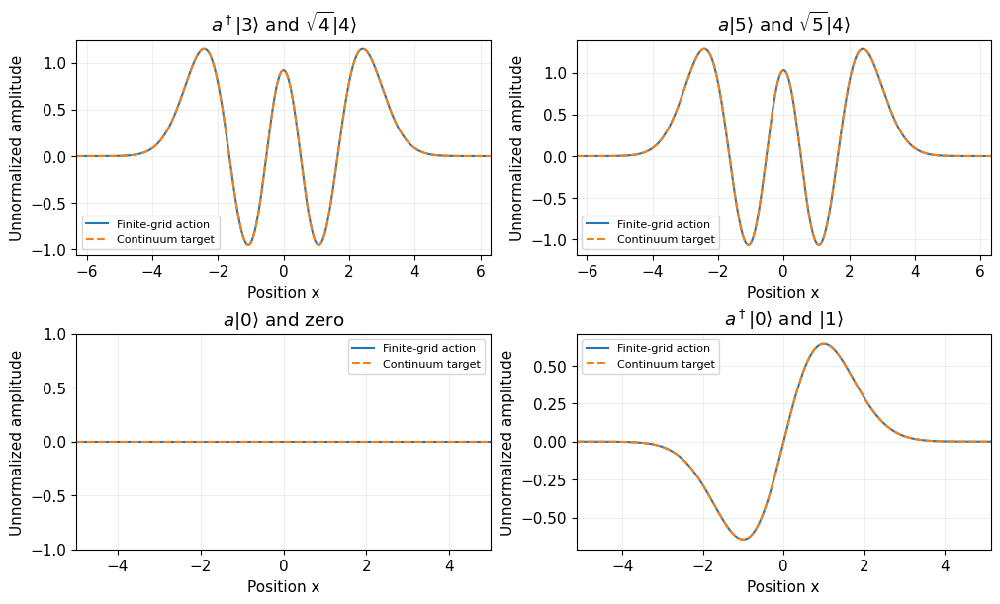

Norm of a|0> before normalization: 9.882e-06
Norm of adag|0> before normalization: 0.99998750
Norm of adag|3>: 1.99990000 (expected sqrt(4) = 2.00000000); norm of a|5>: 2.23592822 (expected sqrt(5) = 2.23606798)


In [20]:
# a†|n> is computed as  adag @ v[:, n]  (matrix times eigenvector), and compared with sqrt(n+1) |n+1>.
# >>> TRY CHANGING (optional): n_raise (default 3) and n_lower (default 5).
PlotLadderActions(oscillator, a, adag, n_raise=3, n_lower=5)

**Question 10:**

**(a)** Look at the position-basis matrices. How do their patterns reflect the $X$ and $P$ terms in the two operators?

**(b)** Compare $a^\dagger|3\rangle$ with $\sqrt{4}|4\rangle$, and $a|5\rangle$ with $\sqrt{5}|4\rangle$. Do the curves agree? What does each operator do to the energy eigenstate?

**(c)** What happens when the lowering operator acts on the ground state? Compare with raising the ground state.

<div><img src="https://clark.physics.illinois.edu/246img/AnsStart.svg" width=200 align=left alt="Answer (start)"></img><br></div>

### ANSWER HERE

**(a):** The matrices flip the values about the diagonal. In matrix a, the first 10 values below the diagonal are blue (about -25) ad the first 10 values above the diagonal are red (about 25). However, for a_dagger the values are flipped (red below and blue on top). This makes sense as the only difference between X and P are a change in sign about P between matrix a and matrix a_dagger.

**(b):** The curves do agree - in each graph the values lay ontop of their associated values. The a_dagger operator raises the energy pulling out the energy eigenstates of the level above while the a operator lowers the energy pulling out the energy eigenstates of the level below.

**(c):** When the lowering opeator acts on the ground state the operator reduces the function to zero. When the raising operator riases the groundstate, the function is raised to the energy eigenstate above the groundstate.

<div><img src="https://clark.physics.illinois.edu/246img/AnsEnd.svg" width=200 align=left alt="Answer (end)"></img><br></div>

### c. Verifying the Norms and the Number Operator

The eigenstates are normalized before we apply the operators. The next plots compare the norms of $a|n\rangle$ and $a^\dagger|n\rangle$ with $\sqrt n$ and $\sqrt{n+1}$ for the first ten eigenstates.

We also calculate the expectation value of $a^\dagger a$, the number operator, in each eigenstate.

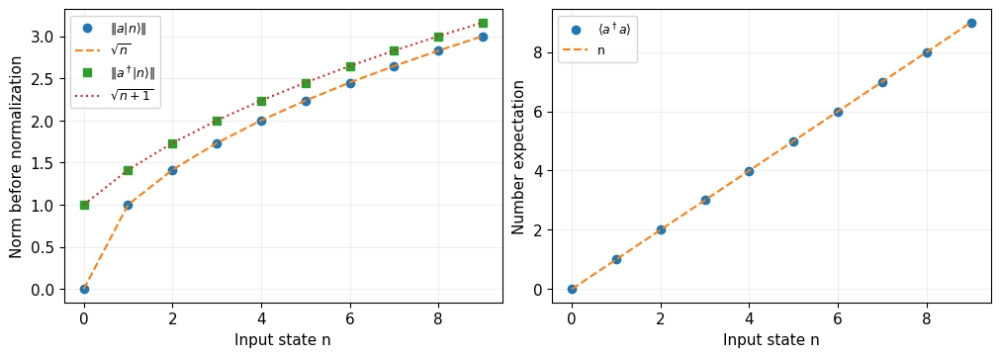

In [21]:
# (Question 11a-b)
PlotLadderNorms(ladder)

**Playground: raise or lower your own state.** A superposition contains several energy levels. A ladder operator acts on **each term**. Does it leave the relative probabilities of those terms unchanged?

For example, the contribution $c_2|2\rangle$ becomes $\sqrt3\,c_2|3\rangle$ when raised. Raising the level-0 contribution instead multiplies its coefficient by $\sqrt1$. These different factors can change the relative weights. The helper applies the same rules you just checked on the grid, now directly to the coefficient list, and then builds the position wavefunction from the eigenstates.

The **norm** is the overall size of the amplitude vector, $\sqrt{\sum_n |c_n|^2}$. The figure titles report it **before** normalization. To compare probabilities, we normalize each nonzero output, then plot its energy probabilities and position density. A zero output cannot be normalized; it is not a state of a particle with zero energy.

**Predict first:** for $|2\rangle$ and $(|0\rangle+|2\rangle)/\sqrt2$, which levels will appear after raising and lowering? Will equal input probabilities remain equal? Write down your predictions in Question 11(c), then run the cell and add a superposition of your own.

These are mathematical operator actions, not ordinary time evolution or a specified measurement procedure. Each component moves one level, but reweighting the components means that the **normalized superposition's mean energy need not change by exactly one unit**.

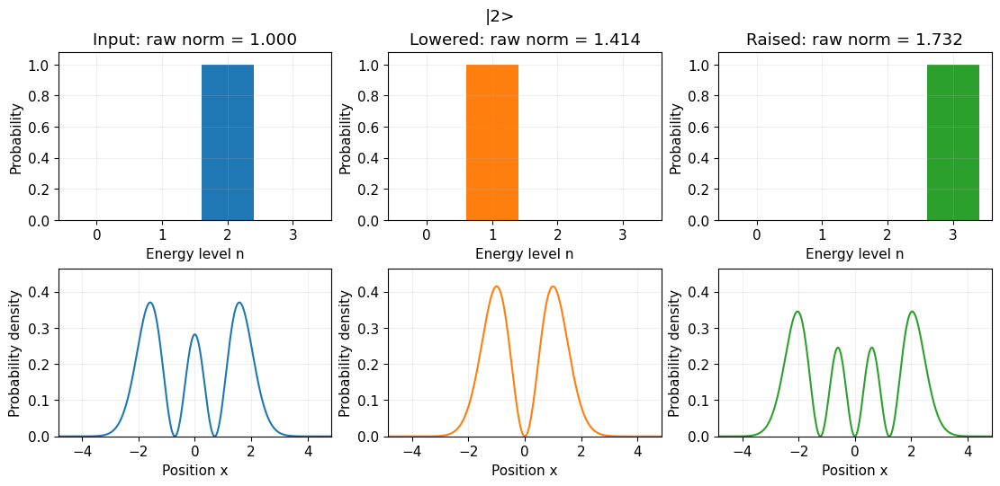

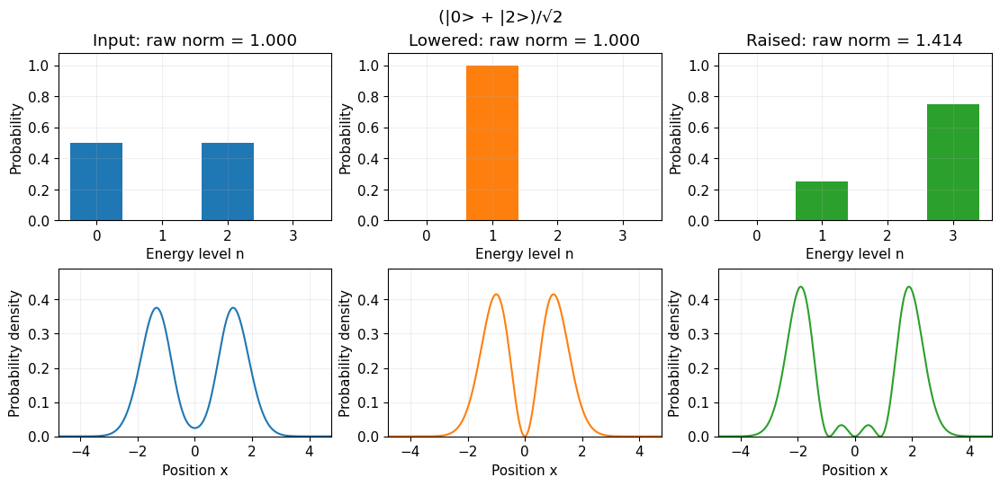

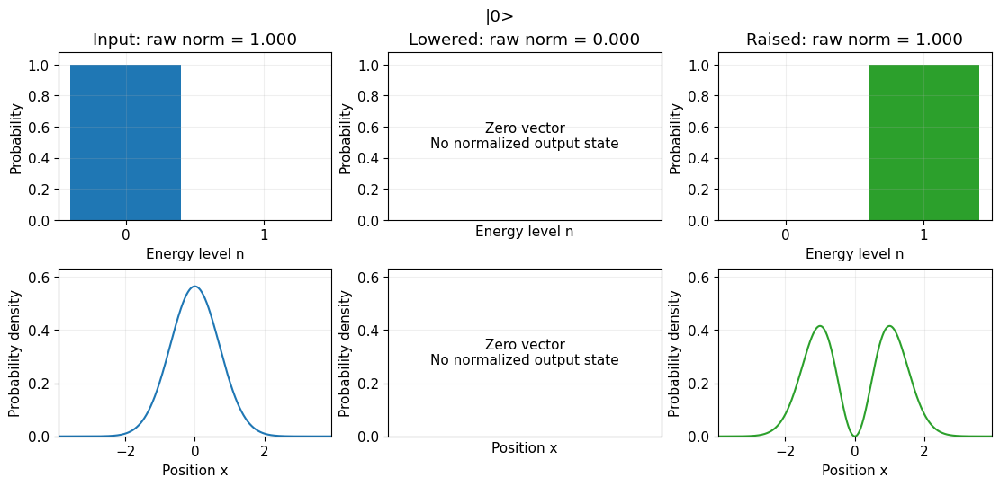

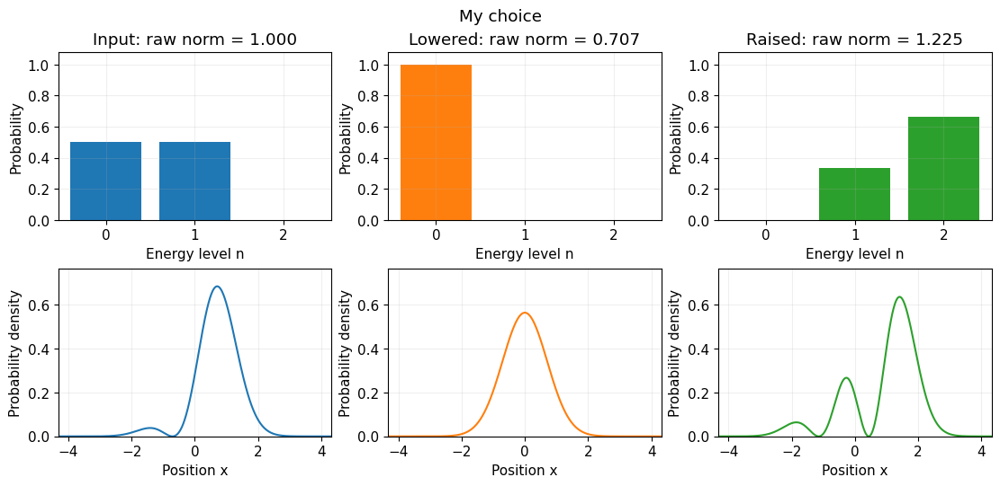

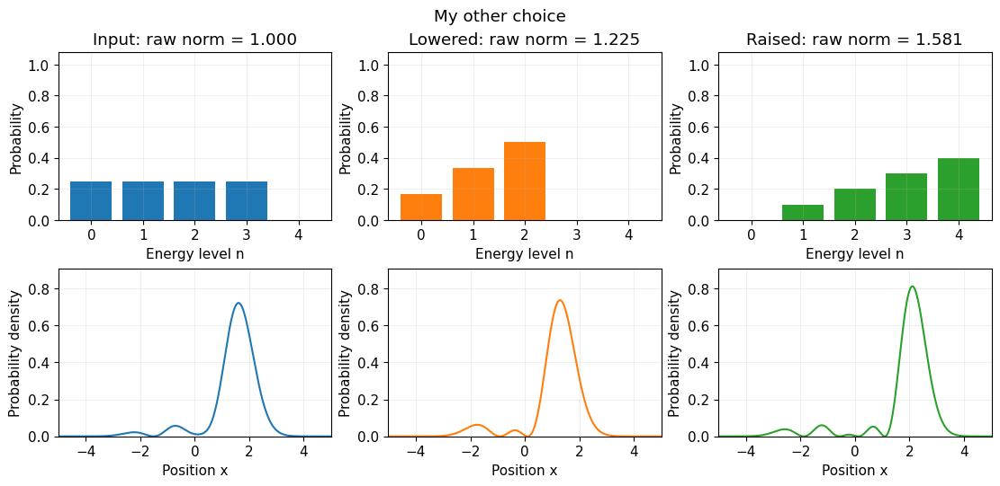

In [22]:
# Playground (Question 11c–d): keep these references and add one custom superposition.
# >>> TRY CHANGING: ADD 'label': [c_0, c_1, ...], using levels 0 to 9.
# Complex entries such as 1j are allowed; the helper normalizes your input.
my_ladder_states = {
    '|2>':             [0, 0, 1],
    '(|0> + |2>)/√2':  [1, 0, 1],
    '|0>':             [1],
    'My choice':       [1, 1],
    'My other choice': [1, 1, 1, 1],
}
if not my_ladder_states:
    raise ValueError('Keep the supplied reference states in my_ladder_states.')
ladder_playground = {}
for ladder_label, ladder_coefficients in my_ladder_states.items():
    ladder_result = LadderSuperposition(oscillator, ladder_coefficients, ladder_label)
    ladder_playground[ladder_label] = ladder_result
    PlotLadderSuperposition(ladder_result)

**Question 11:**

**(a)** Do the norms of the lowered and raised states agree with $\sqrt n$ and $\sqrt{n+1}$?

**(b)** What values do you obtain for $\langle a^\dagger a\rangle$ in the first ten eigenstates?

**(c) (Playground)** Record your predictions before running the playground cell. For the two reference inputs $|2\rangle$ and $(|0\rangle+|2\rangle)/\sqrt2$, which levels remain after raising or lowering? Do equal input weights remain equal? Explain one result using the square-root factors, and distinguish the raw norm from a normalized probability.

**(d) (Playground)** Add one custom superposition and describe its before/after energy probabilities and position densities. Finally, explain why lowering $|0\rangle$ produces no normalized output state, whereas raising it does.

<div><img src="https://clark.physics.illinois.edu/246img/AnsStart.svg" width=200 align=left alt="Answer (start)"></img><br></div>

### ANSWER HERE

**(a):** Yes, the norms of the raised and lowered states agree with sqrt(n) and sqrt(n + 1). Both lines pass through all of the first 10 values of the raised and lowered states.

**(b):** The first ten eigenstates of < a_dagger a > are: 0, 1, 2, 3, 4, 5, 6, 7, 8, 9.

**(c):** Prediction: I predict that after raising, all levels will be boosted a level higher. When lowered, I predict that the state that the groundstate portion of (|0> + |2>)/sqrt(2) will go to zero while the the |2> half will be lowered as normal.

Results: Only levels above the groundstate remain after lowering. When doing this, equal input weights do not remain equal anymore. When My Choice gets lowered the groundstate goes to zero. This affects the full normalization of the process as the norm becomes .707 while for the plain lowering of |2> the value should have a norm of 1. Since the norm isn't 1, the weights are no longer equal as they aren't representing the decrease of the function between levels.

**(d):** For My Choice, the initial state is an equal split between states 0, and 1. After lowering it, the probability density shifts from being centered about ~1 to a gaussian centered about zero. When the funciton is raised the main peak remains centered ~1 but it also gains two secondary peaks centered at ~-.5 and ~-2.

Lowering the matri returns the eigenvalues below the level you are currently at. As there is no level below the groundstate, the lowering operator instead returns 0 as that is the only eigenvalue that makes the matrix true. As zero is returned, the matrix becomes nonnormalizable as zero can't be normalized. However, when the groundstate is raised, it returns the eigenvalues of the level above. As the values are nonzero, the values can be normalized such that the matrix is normalizable.

<div><img src="https://clark.physics.illinois.edu/246img/AnsEnd.svg" width=200 align=left alt="Answer (end)"></img><br></div>

### d. Operators in the Harmonic Oscillator Basis

We now write $a$, $a^\dagger$, and $a^\dagger a$ in the harmonic oscillator energy basis. The next images show the first ten rows and columns of each matrix. A column labels the input state $|n\rangle$ and a row labels the output state $|m\rangle$.

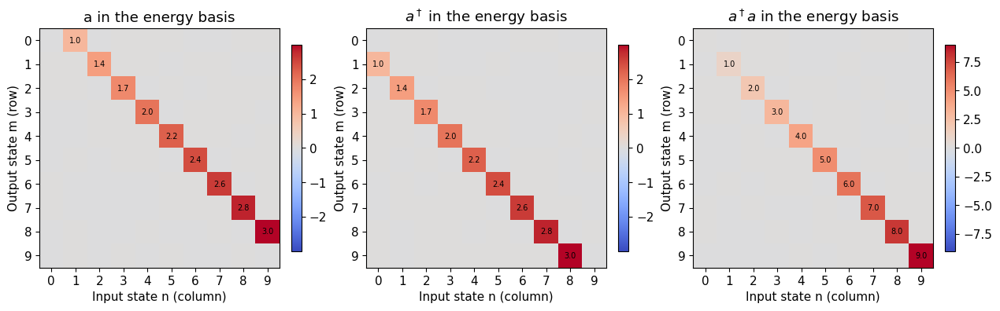

Number-operator diagonal: [9.76560e-11 9.99975e-01 1.99990e+00 2.99978e+00 3.99960e+00 4.99938e+00
 5.99910e+00 6.99878e+00 7.99840e+00 8.99798e+00]


In [23]:
# Energy-basis matrix elements  <m|A|n> = sum_j psi_m(x_j) (A psi_n)_j,  i.e.  v.T @ (A @ v).
PlotEnergyOperators(ladder)

**The position operator in the energy basis.** Since $X=(a+a^\dagger)/\sqrt2$, the ladder-operator rules predict

$\langle n-1|X|n\rangle=\sqrt{n/2},\qquad \langle n+1|X|n\rangle=\sqrt{(n+1)/2},$

and zero for every other pair $m,n$. The next cell computes $\langle m|X|n\rangle=\sum_j \psi_m(x_j)\,x_j\,\psi_n(x_j)$ directly from the numerical eigenstates and compares it with this prediction.

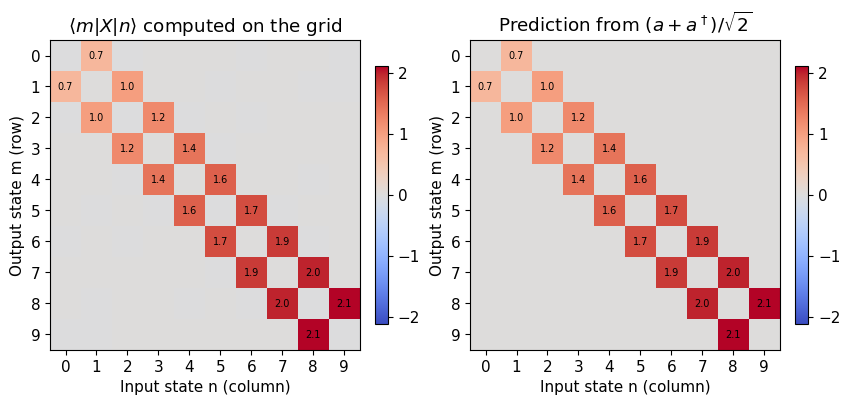

Largest difference between computed and predicted entries: 1.2e-04


In [24]:
n_show = 10
v10 = oscillator['v'][:, :n_show]                   # eigenstates |0> ... |9> as columns

# Computed:  <m|X|n> = sum_j psi_m(x_j) x_j psi_n(x_j)   for all m, n at once.
X_energy = v10.T @ (X @ v10)

# Predicted from X = (a + a†)/sqrt(2), a|n> = sqrt(n)|n-1>, a†|n> = sqrt(n+1)|n+1>:
#   entry (row n-1, column n) = sqrt(n/2)  just above the diagonal,
#   entry (row n+1, column n) = sqrt((n+1)/2) just below it; all others are 0.
n = np.arange(1, n_show)
X_ladder = np.diag(np.sqrt(n / 2), k=1) + np.diag(np.sqrt(n / 2), k=-1)

PlotMatrices([X_energy, X_ladder],
             [r'$\langle m|X|n\rangle$ computed on the grid', r'Prediction from $(a+a^\dagger)/\sqrt{2}$'])
print(f"Largest difference between computed and predicted entries: {abs(X_energy - X_ladder).max():.1e}")

**Question 12:**

**(a)** On which side of the diagonal are the nonzero entries of $a$ and $a^\dagger$? Use the row and column labels to explain how this represents lowering or raising a state.

**(b)** What are the diagonal entries of $a^\dagger a$? Why does this matrix make sense for the number operator?

**(c)** Which entries of $X$ are nonzero in the energy basis, and do they agree with the ladder-operator prediction? Use this to explain your observation in Question 8(d): why can $\langle x\rangle$ oscillate for $(|0\rangle+|1\rangle)/\sqrt2$ but not for $(|0\rangle+|2\rangle)/\sqrt2$?

<div><img src="https://clark.physics.illinois.edu/246img/AnsStart.svg" width=200 align=left alt="Answer (start)"></img><br></div>

### ANSWER HERE

**(a):** For a, the values are on the right side of the diagonal while for a_dagger the values are on the left side of the diagonal. This represents raising or lowering a state as the rows are the output state. For an input of state 1, if the state is lowered it will go to state 0. The value that has an input of 1 and an output of 0 is above (1, 1) which is to the right of the diagonal. Similarly, if it was raised it would go up a level. For the graph this is below (1, 1) which is in the portion of the matrix that is to the left of the diagonal.

**(b):** The diagonal of a_dagger @ a is n. This makes sense as these functions should undo each other - if you go up and then come down using ladder operators you return to the same spot that you left. This value you should return to should be the initital state that you left.

**(c):** The offdiagonal terms are nonzero in the energy basis. These values agree with the ladder-operator prediction as the largest difference between the predictions and numerical terms is 1.2e-4 (ie the values match to ~ 4 decimal places). These values are x evaulated against the basis states m and n. Since m and n mapped onto x, and the imaginary exponential component remained, the value rotates. However, in the case of 0 + 1, the imaginary component gets squared causing the imaginary exponential to become real and nonoscillatory.

<div><img src="https://clark.physics.illinois.edu/246img/AnsEnd.svg" width=200 align=left alt="Answer (end)"></img><br></div>

### e. Numerical Limitations

So far, our calculations have agreed well with the expected oscillator results. Now we ask: **have we given the wavefunction enough room?**

The real harmonic oscillator has no walls, but our computer calculation covers only a finite interval. At the two ends of that interval, the program forces the wavefunction to be zero. This works well when the state has already become very small before reaching either end. Higher-energy states extend farther from the center, so they need a larger interval.

The next cell compares energies through $n=100$ for two intervals: $-10\le x\le10$ and $-20\le x\le20$. Their full lengths are $L=20$ and $L=40$. The distance from the center to either end is called the **half-width**, written $h$ below. In `domain_halves`, you enter $h$, not the full length $L=2h$. The spacing between neighboring grid points stays the same in every calculation.

**A rough prediction.** From Exercise 2b, the classical turning point of level $n$ is at $x_t=\sqrt{2n+1}$. Setting this distance equal to the half-width gives

$$n_{\mathrm{edge}}\approx\frac{h^2-1}{2}.$$

Around this level, the state needs about as much room as the calculation provides. The cell prints this estimate and marks it with a dotted vertical line when it lies within the plotted range. It is a guide, not a sharp cutoff: the quantum wavefunction has tails beyond the turning point, so disagreement can begin earlier and grow gradually.

**Why can the energies rise?** If an artificial edge cuts into a state, forcing its wavefunction to reach zero there can make it bend more sharply. More rapid spatial variation is associated with greater kinetic energy. This is why a calculation with too little room can give energies that are too high. Small errors also come from representing a continuous wavefunction by grid points; those errors can shift energies downward. Here, focus on the large upward bend caused by the nearby edges.

half =    10 (L = 20):  turning point reaches the edge near n ≈ 50
half =    20 (L = 40):  turning point reaches the edge near n ≈ 200
half =     7 (L = 14):  turning point reaches the edge near n ≈ 24


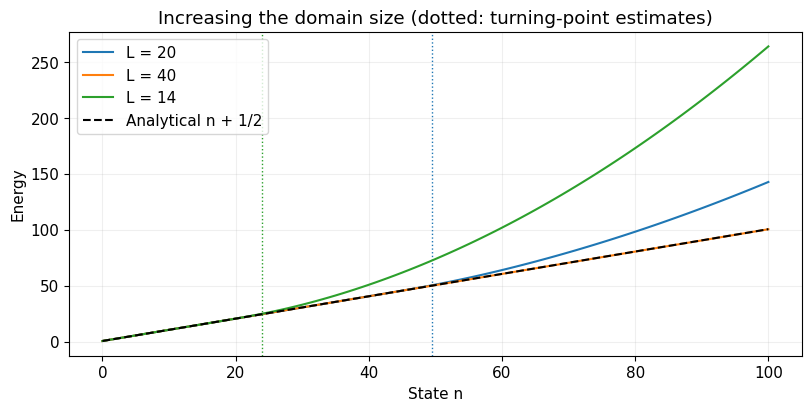

In [25]:
# >>> TRY CHANGING (Question 13b): ADD a domain half-width to this list (default [10.0, 20.0]).
domain_halves = [10.0, 20.0, 7.0]

# Turning-point estimate: the turning point x_t = sqrt(2 E_n) = sqrt(2n + 1) reaches the
# grid edge when 2n + 1 = half^2, i.e. at n = (half^2 - 1)/2.
for h in domain_halves:
    print(f"half = {h:5g} (L = {2 * h:g}):  turning point reaches the edge near n ≈ {(h**2 - 1) / 2:.0f}")

grid_comparison = GridComparison(domain_halves, dx=0.01, n_max=100)
PlotGridComparison(grid_comparison)

**Question 13:**

**(a)** Where do the calculated energies begin to depart noticeably from $E_n=n+1/2$ for $L=20$? What changes when $L$ is increased to 40? Explain why higher-energy states need more room in position space.


**(b) (Playground)** Give the wavefunction less room: add a half-width between `6.0` and `9.0` to `domain_halves`, keeping the two original values.

Before running, write down your chosen half-width and use $n_{\mathrm{edge}}\approx(h^2-1)/2$ to estimate which level will reach the edge. Do you expect your energy curve to leave the dashed reference curve at a lower or a higher level than the $L=20$ curve?

Run the cell and describe what you see. Does the noticeable upward bend occur in roughly the region you predicted? An approximate range of levels is enough. Using the explanation above, explain why moving the edges farther away would help, and point to one comparison in the plot that supports your answer.

<div><img src="https://clark.physics.illinois.edu/246img/AnsStart.svg" width=200 align=left alt="Answer (start)"></img><br></div>

### ANSWER HERE

**(a):** The function begins to noticably diverge after crossing the turning point of n = 50. This is not the case when L = 40; in this situation the energy matches the analytical value the whole way to state 100. This large change occurs as h is changed between sessions. Since h is increased, the matrix has more space to solve the function. When there isn't enough space (as in the case of L = 20), the edges occur prematurely. This sets the boundry energies to zero causing the computer to think there is a larger change in energy than there really is. Higher energy states need more room so that they can accurately be calculated without this error about the edges significantly reducing accuracy.

**(b):** Half_width: 7, Prediciton: nedge ~24; I expect the energy curve to diverge before the L = 20 curve.

Results: The graph begins diverging just after n of 24 just as predicted. Moving edges away would help prevent this divergence as it gives the algorithm more space to calculate values before hitting a hard edge of zero. Just looking between h = 7 and h = 10 can show why this is important; between the two values, h = 10 diverges much later (~25 edges). If similarly, when the value is increased to 20, the expected edge of divergence is n = 200 (which isn't even on the graph). As the edge goes up with h, increasing h will allow for more values to be calculated before resulting in significat divergence.

<div><img src="https://clark.physics.illinois.edu/246img/AnsEnd.svg" width=200 align=left alt="Answer (end)"></img><br></div>

**The position–momentum commutator**

We learned that $[X,P]=iI$ in units where $\hbar=1$. Let’s test this by looking at the imaginary part of the first $10\times10$ entries of the computed commutator. The expected identity matrix is shown beside it.

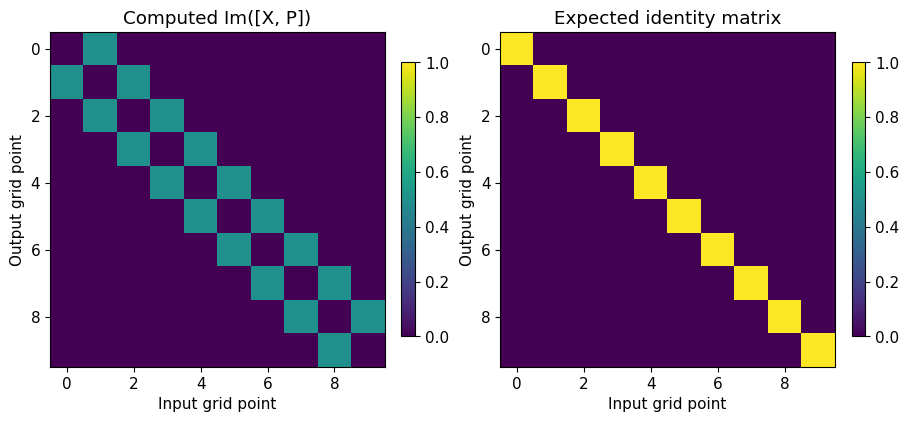

Trace of the computed [X, P]:   0.000e+00
Trace of iI for this grid:       1999i   (N = 1999 grid points)


In [26]:
# The commutator [X, P] = XP - PX, using the matrices X and P from Exercise 3a.
commutator = X @ P - P @ X

# Imaginary part of the first 10 x 10 entries (the real part is zero).
PlotCommutator(commutator[:10, :10].toarray().imag)

# Trace = sum of the diagonal entries.
print(f"Trace of the computed [X, P]:   {abs(commutator.diagonal().sum()):.3e}")
print(f"Trace of iI for this grid:       {X.shape[0]}i   (N = {X.shape[0]} grid points)")

The computed matrix has entries $1/2$ immediately next to the diagonal, rather than ones on the diagonal. A finite matrix cannot reproduce the commutation relation exactly, since

$\operatorname{Tr}(XP-PX)=\operatorname{Tr}(XP)-\operatorname{Tr}(PX)=0,$

where we used the fact that the trace does not change when the two factors are interchanged. In contrast, $\operatorname{Tr}(iI)=iN$ for an $N\times N$ matrix.

**Question 14:**

**(a)** How does the computed commutator differ from the expected matrix? Use the trace argument to explain why finite matrices cannot satisfy $[X,P]=iI$ exactly.

<div><img src="https://clark.physics.illinois.edu/246img/AnsStart.svg" width=200 align=left alt="Answer (start)"></img><br></div>

### ANSWER HERE

**(a):** Rather than resulting in the same matricies, the computed commutator differs from the expected matrix. Rather than being 1 along the diagonals, it is 1/2 on both off-diagonals. Since we assumed that flipping the values about would not change the two factors, the values commute with each other and the trace of the commutator results in zero. Since this relation is used, the computed commutator differs from the matrix in that it results in zero rather than iI.

<div><img src="https://clark.physics.illinois.edu/246img/AnsEnd.svg" width=200 align=left alt="Answer (end)"></img><br></div>

---

## Before you submit

1. Fill in your name, the date, and the time you spent at the top.
2. Answer Questions 1–14, including every **(Playground)** part, in the Markdown answer cells or a separate labelled document. Explain the physics and identify supporting results. Question 15 is optional.
3. Keep all plots and numerical output referred to in your answers visible. For playground parts, leave the values you tried in the code lists so they reappear when the notebook is rerun.
4. Include and label any extra figures or calculations that support your answers.

## Making a PDF

1. Set `SHOW_ANIMATIONS = False` in the import/settings cell. Animations do not print; the static figures contain the evidence needed for every question.
2. Restart and run the whole notebook so the saved output matches the code: use **Runtime > Restart session and run all** in Colab, or **Kernel > Restart Kernel and Run All Cells** in Jupyter/JupyterLab.
3. Save your notebook. In Colab, download the `.ipynb` copy as well.
4. Use your notebook interface’s print command, then select **Save as PDF**. If the interface does not offer printing, export to HTML and print that in a browser. Enable background graphics and fit to page width so plots are not clipped.
5. Choose either format: **(A)** one PDF containing answers and supporting output in question order, or **(B)** a separate answers PDF that identifies the figures and results in your executed notebook by question and plot title. Include the parameter choices you discuss in either format.
6. Inspect your PDF for missing answers or clipped text; for format A, also check that the figures are legible. Submit your PDF **and the executed `.ipynb` file** in both cases. For format B, you do not need to print the notebook.

---

**Acknowledgements:** Adapted from Bryan Clark’s original *Harmonic Oscillator* notebook (© 2025)